# Fig. 3 all sites: cap2000 trait predictions and FLUXNET context

This notebook browses the generated 2022 biweekly trait predictions, Sentinel-2 spectral-index context, ERA5-Land climate context, and FLUXNET context plots for the 37 filtered sites.
Trait predictions are loaded from the prediction table recorded in `run_summary.json`; the current run mode is shown below.


In [20]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import zarr
from IPython.display import Image, Markdown, display
from scipy.optimize import curve_fit
from scipy.stats import spearmanr

PAPER_ROOT = Path("/home/chaonan.ji/data/projects/ecospectra/docs/paper1_perspective")
ECOSPECTRA_ROOT = Path("/home/chaonan.ji/data/projects/ecospectra")
TABLE_DIR = PAPER_ROOT / "tables" / "fig3_all_sites_cap2000_flux_traits"
FIG_DIR = PAPER_ROOT / "figures" / "generated" / "fig3_all_sites_cap2000_flux_traits"
WORLD_COVER_DIR = ECOSPECTRA_ROOT / "input_data" / "enmap" / "landcover" / "worldcover2021_30m_site_aligned_zarr"
FLUXNET_SHUTTLE = ECOSPECTRA_ROOT / "input_data" / "fluxnet_shuttle.csv"

RUN_SUMMARY = json.loads((TABLE_DIR / "run_summary.json").read_text())
MAPPING = pd.read_csv(TABLE_DIR / "site_fluxnet_mapping.csv")
FLUX = pd.read_csv(TABLE_DIR / "all_sites_fluxnet_context_2022_biweekly.csv", parse_dates=["date"])
ERA5 = pd.read_csv(TABLE_DIR / "all_sites_era5_context_2022_biweekly.csv", parse_dates=["date"])
PRED_PATH = Path(RUN_SUMMARY.get("trait_predictions_summary", TABLE_DIR / "all_sites_cap2000_biweekly_trait_predictions_2022_summary.csv"))
PRED = pd.read_csv(PRED_PATH, parse_dates=["date"])
SPECTRAL = pd.read_csv(TABLE_DIR / "all_sites_cap2000_biweekly_spectral_context_2022.csv", parse_dates=["date"])

FLUX_LABELS = {
    "GPP_NT_VUT_REF": "GPP",
    "NEP_VUT_REF": "NEP",
    "ET_F_MDS_mm_day": "ET",
    "VPD_F_MDS": "VPD",
    "SWC_F_MDS_1": "SWC1",
    "SWC_F_MDS_2": "SWC2",
    "WUE_GPP_ET": "WUE",
    "RECO_NT_VUT_REF": "Reco",
}
SPECTRAL_LABELS = ["NDVI", "EVI", "NDWI", "NBR", "CIRE", "NDRE", "MSI"]
ERA5_LABELS = {
    "2m_temperature_C": "Tair",
    "total_precipitation_mm": "P",
    "surface_solar_radiation_downwards_MJ_m2_day": "SWdown",
    "volumetric_soil_water_layer_1": "SWC",
}

sns.set_theme(style="white", context="paper")
plt.rcParams.update({
    "figure.dpi": 130,
    "savefig.dpi": 300,
    "axes.grid": False,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.family": "DejaVu Sans",
})


## Run summary


In [21]:
display(Markdown(
    f"- sites requested: **{RUN_SUMMARY['sites_requested']}**\n"
    f"- sites with trait predictions: **{RUN_SUMMARY['sites_predicted']}**\n"
    f"- sites with 2022 ERA5 values: **{RUN_SUMMARY['sites_with_era5_values']}**\n"
    f"- sites with 2022 FLUXNET values: **{RUN_SUMMARY['sites_with_fluxnet_values']}**\n"
    f"- prediction mode: **{RUN_SUMMARY.get('prediction_mode', 'unknown')}**\n"
    f"- prediction table: `{PRED_PATH}`\n"
    f"- multipage PDF: `{RUN_SUMMARY['figures'][0]}`"
))

display(MAPPING[[
    "site_id", "site_name", "fluxnet_site_id", "fluxnet_site_name",
    "first_year", "last_year", "distance_km", "has_2022",
]])


- sites requested: **37**
- sites with trait predictions: **34**
- sites with 2022 ERA5 values: **37**
- sites with 2022 FLUXNET values: **22**
- prediction mode: **b5b6_cap5000_transformer_lai_lma**
- prediction table: `/home/chaonan.ji/data/projects/ecospectra/docs/paper1_perspective/tables/fig3_all_sites_cap2000_flux_traits/all_sites_b5b6_cap5000_transformer_biweekly_trait_predictions_2022_summary.csv`
- multipage PDF: `/home/chaonan.ji/data/projects/ecospectra/docs/paper1_perspective/figures/generated/fig3_all_sites_cap2000_flux_traits/all_sites_cap2000_traits_flux_2022.pdf`

,site_id,site_name,fluxnet_site_id,fluxnet_site_name,first_year,last_year,distance_km,has_2022
0,0,Neustift,AT-Neu,Neustift,2002.0,2020.0,0.210825,False
1,2,Chamau,CH-Cha,Chamau,2005.0,2024.0,0.003999,True
2,3,Laegern,CH-Lae,Laegern,2004.0,2024.0,0.003761,True
3,6,Dagowsee,NaN,NaN,NaN,NaN,NaN,False
4,7,Gebesee,DE-Geb,Gebesee,2020.0,2024.0,0.003939,True
5,9,Hainich,DE-Hai,Hainich,2000.0,2024.0,0.002603,True
6,10,Huetelmoor,DE-Hte,Huetelmoor,2009.0,2018.0,0.002549,False
7,11,Klingenberg,DE-Kli,Klingenberg,2018.0,2024.0,0.009379,True
8,13,Leinefelde,DE-Lnf,Leinefelde,2002.0,2024.0,0.001890,True
9,15,Schechenfilz Nord,NaN,NaN,NaN,NaN,NaN,False


## ERA5-Land variable coverage


In [22]:
era5_coverage = []
for col, label in ERA5_LABELS.items():
    values = pd.to_numeric(ERA5[col], errors="coerce") if col in ERA5.columns else pd.Series(dtype=float)
    era5_coverage.append({
        "variable": label,
        "source_column": col,
        "non_na_rows": int(values.notna().sum()),
        "sites_with_data": int(ERA5.loc[values.notna(), "site_id"].nunique()) if len(values) else 0,
    })
display(pd.DataFrame(era5_coverage))


,variable,source_column,non_na_rows,sites_with_data
0,Tair,2m_temperature_C,962,37
1,P,total_precipitation_mm,962,37
2,SWdown,surface_solar_radiation_downwards_MJ_m2_day,962,37
3,SWC,volumetric_soil_water_layer_1,962,37


## FLUXNET variable coverage


In [23]:
coverage = []
for col, label in FLUX_LABELS.items():
    values = pd.to_numeric(FLUX[col], errors="coerce") if col in FLUX.columns else pd.Series(dtype=float)
    coverage.append({
        "variable": label,
        "source_column": col,
        "non_na_rows": int(values.notna().sum()),
        "sites_with_data": int(FLUX.loc[values.notna(), "site_id"].nunique()) if len(values) else 0,
    })
display(pd.DataFrame(coverage))


,variable,source_column,non_na_rows,sites_with_data
0,GPP,GPP_NT_VUT_REF,500,20
1,NEP,NEP_VUT_REF,526,21
2,ET,ET_F_MDS_mm_day,540,22
3,VPD,VPD_F_MDS,572,22
4,SWC1,SWC_F_MDS_1,494,19
5,SWC2,SWC_F_MDS_2,431,17
6,WUE,WUE_GPP_ET,492,20
7,Reco,RECO_NT_VUT_REF,500,20


## Trait prediction coverage


In [24]:
pred_cov = (
    PRED.groupby(["site_id", "model", "trait"], as_index=False)
    .agg(
        n_dates=("date", "nunique"),
        n_non_na=("prediction_median", lambda s: int(pd.to_numeric(s, errors="coerce").notna().sum())),
        median_pixels=("n_pixels", "median"),
    )
)
display(pred_cov)

missing_trait_sites = sorted(set(MAPPING.site_id.astype(int)) - set(PRED.site_id.astype(int)))
display(Markdown(f"Sites without trait predictions: `{missing_trait_sites}`"))


,site_id,model,trait,n_dates,n_non_na,median_pixels
0,0,transformer_b5b6_cap5000,LAI,26,26,121.0
1,0,transformer_b5b6_cap5000,LMA,26,26,121.0
2,2,transformer_b5b6_cap5000,LAI,26,26,190.0
3,2,transformer_b5b6_cap5000,LMA,26,26,190.0
4,3,transformer_b5b6_cap5000,LAI,26,24,900.0
...,...,...,...,...,...,...
63,54,transformer_b5b6_cap5000,LMA,26,26,798.0
64,56,transformer_b5b6_cap5000,LAI,26,26,683.0
65,56,transformer_b5b6_cap5000,LMA,26,26,683.0
66,57,transformer_b5b6_cap5000,LAI,26,26,833.0


Sites without trait predictions: `[7, 22, 47]`

## Sentinel-2 spectral-index coverage


In [25]:
spectral_coverage = []
for label in SPECTRAL_LABELS:
    col = f"{label}_median"
    values = pd.to_numeric(SPECTRAL[col], errors="coerce") if col in SPECTRAL.columns else pd.Series(dtype=float)
    spectral_coverage.append({
        "index": label,
        "source_column": col,
        "non_na_rows": int(values.notna().sum()),
        "sites_with_data": int(SPECTRAL.loc[values.notna(), "site_id"].nunique()) if len(values) else 0,
    })
display(pd.DataFrame(spectral_coverage))


,index,source_column,non_na_rows,sites_with_data
0,NDVI,NDVI_median,792,34
1,EVI,EVI_median,792,34
2,NDWI,NDWI_median,792,34
3,NBR,NBR_median,792,34
4,CIRE,CIRE_median,792,34
5,NDRE,NDRE_median,792,34
6,MSI,MSI_median,792,34


## Coupling analysis setup

The next cells build a unified biweekly table and analyze lagged coupling. Trait variables use the median prediction in the active prediction table. Positive lag means the row variable leads the target variable.


In [26]:
def dominant_worldcover(site_id, window=31):
    path = WORLD_COVER_DIR / f"site_{int(site_id)}_worldcover2021_30m.zarr"
    if not path.exists():
        return np.nan
    arr = zarr.open(str(path), mode="r")
    data = np.asarray(arr[0])
    cy, cx = data.shape[0] // 2, data.shape[1] // 2
    half = int(window) // 2
    sub = data[max(0, cy-half):cy+half+1, max(0, cx-half):cx+half+1]
    vals, counts = np.unique(sub[np.isfinite(sub) & (sub > 0)], return_counts=True)
    if len(vals) == 0:
        return np.nan
    return int(vals[np.argmax(counts)])

WORLD_COVER_LABELS = {
    10: "Tree cover",
    20: "Shrubland",
    30: "Grassland",
    40: "Cropland",
    50: "Built-up",
    60: "Bare/sparse",
    70: "Snow/ice",
    80: "Water",
    90: "Wetland",
    95: "Mangroves",
    100: "Moss/lichen",
}

shuttle = pd.read_csv(FLUXNET_SHUTTLE, usecols=["site_id", "igbp"]).rename(columns={"site_id": "fluxnet_site_id"})
site_meta = MAPPING.merge(shuttle, on="fluxnet_site_id", how="left")
site_meta["worldcover_code"] = site_meta["site_id"].map(dominant_worldcover)
site_meta["worldcover_class"] = site_meta["worldcover_code"].map(WORLD_COVER_LABELS).fillna("unclassified")
site_meta["pft_group"] = site_meta["igbp"].fillna(site_meta["worldcover_class"]).fillna("unclassified")
flux_availability_mask = pd.Series(False, index=FLUX.index)
for col in ["GPP_NT_VUT_REF", "NEP_VUT_REF", "ET_F_MDS_mm_day"]:
    if col in FLUX.columns:
        flux_availability_mask = flux_availability_mask | pd.to_numeric(FLUX[col], errors="coerce").notna()
site_meta["has_flux_values"] = site_meta["site_id"].isin(FLUX.loc[flux_availability_mask, "site_id"].unique())

trait_wide = (
    PRED.groupby(["site_id", "date", "trait"], as_index=False)["prediction_median"]
    .median()
    .pivot(index=["site_id", "date"], columns="trait", values="prediction_median")
    .rename(columns={
        "LAI": "trait_LAI",
        "LMA": "trait_LMA",
        "Nitrogen": "trait_N",
        "Chlorophyll": "trait_Chl",
        "Lignin": "trait_Lignin",
    })
    .reset_index()
)

s2_wide = SPECTRAL.rename(columns={f"{name}_median": f"S2_{name}" for name in SPECTRAL_LABELS})
era5_wide = ERA5.rename(columns={
    "2m_temperature_C": "ERA5_Tair",
    "total_precipitation_mm": "ERA5_P",
    "surface_solar_radiation_downwards_MJ_m2_day": "ERA5_SWdown",
    "volumetric_soil_water_layer_1": "ERA5_SWC",
})
flux_wide = FLUX.rename(columns={
    "GPP_NT_VUT_REF": "Flux_GPP",
    "NEP_VUT_REF": "Flux_NEP",
    "ET_F_MDS_mm_day": "Flux_ET",
    "VPD_F_MDS": "Flux_VPD",
    "SWC_F_MDS_1": "Flux_SWC1",
    "SWC_F_MDS_2": "Flux_SWC2",
    "WUE_GPP_ET": "Flux_WUE",
    "RECO_NT_VUT_REF": "Flux_Reco",
})

analysis = trait_wide.merge(
    s2_wide[["site_id", "date"] + [f"S2_{name}" for name in SPECTRAL_LABELS]],
    on=["site_id", "date"],
    how="outer",
).merge(
    era5_wide[["site_id", "date", "ERA5_Tair", "ERA5_P", "ERA5_SWdown", "ERA5_SWC"]],
    on=["site_id", "date"],
    how="outer",
).merge(
    flux_wide[["site_id", "date", "Flux_GPP", "Flux_NEP", "Flux_ET", "Flux_VPD", "Flux_SWC1", "Flux_SWC2", "Flux_WUE", "Flux_Reco"]],
    on=["site_id", "date"],
    how="outer",
).merge(
    site_meta[["site_id", "site_name", "fluxnet_site_id", "igbp", "worldcover_class", "pft_group", "has_flux_values"]],
    on="site_id",
    how="left",
)

analysis = analysis.sort_values(["site_id", "date"]).reset_index(drop=True)
analysis_path = TABLE_DIR / "all_sites_unified_biweekly_analysis_2022.csv"
analysis.to_csv(analysis_path, index=False)

analysis_diff = analysis.copy()
numeric_cols = [
    col for col in analysis_diff.columns
    if col.startswith(("trait_", "S2_", "ERA5_", "Flux_"))
]
analysis_diff[numeric_cols] = (
    analysis_diff.groupby("site_id", group_keys=False)[numeric_cols]
    .apply(lambda frame: frame.apply(pd.to_numeric, errors="coerce").diff())
)

display(Markdown(f"Unified analysis table written to `{analysis_path}`"))
display(site_meta[["site_id", "site_name", "fluxnet_site_id", "igbp", "worldcover_class", "pft_group", "has_flux_values"]])
display(analysis.head(20))


Unified analysis table written to `/home/chaonan.ji/data/projects/ecospectra/docs/paper1_perspective/tables/fig3_all_sites_cap2000_flux_traits/all_sites_unified_biweekly_analysis_2022.csv`

,site_id,site_name,fluxnet_site_id,igbp,worldcover_class,pft_group,has_flux_values
0,0,Neustift,AT-Neu,GRA,Grassland,GRA,False
1,2,Chamau,CH-Cha,GRA,Grassland,GRA,True
2,3,Laegern,CH-Lae,MF,Tree cover,MF,True
3,6,Dagowsee,NaN,NaN,Tree cover,Tree cover,False
4,7,Gebesee,DE-Geb,CRO,Cropland,CRO,True
5,9,Hainich,DE-Hai,DBF,Tree cover,DBF,True
6,10,Huetelmoor,DE-Hte,WET,Wetland,WET,False
7,11,Klingenberg,DE-Kli,CRO,Cropland,CRO,True
8,13,Leinefelde,DE-Lnf,DBF,Tree cover,DBF,True
9,15,Schechenfilz Nord,NaN,NaN,Tree cover,Tree cover,False


,site_id,date,trait_LAI,trait_LMA,S2_NDVI,S2_EVI,S2_NDWI,S2_NBR,S2_CIRE,S2_NDRE,...,Flux_SWC1,Flux_SWC2,Flux_WUE,Flux_Reco,site_name,fluxnet_site_id,igbp,worldcover_class,pft_group,has_flux_values
0,0,2022-01-08,3.827882,89.096330,0.593992,0.253050,0.257448,0.459717,1.524898,0.420671,...,NaN,NaN,NaN,NaN,Neustift,AT-Neu,GRA,Grassland,GRA,False
1,0,2022-01-22,3.576272,89.662766,0.492114,0.258983,0.281096,0.380320,1.128631,0.354788,...,NaN,NaN,NaN,NaN,Neustift,AT-Neu,GRA,Grassland,GRA,False
2,0,2022-02-05,3.263499,90.384830,0.376308,0.251262,0.169385,0.270944,0.850516,0.288454,...,NaN,NaN,NaN,NaN,Neustift,AT-Neu,GRA,Grassland,GRA,False
3,0,2022-02-19,2.641862,89.178665,0.328087,0.247690,0.112487,0.214799,0.710981,0.252754,...,NaN,NaN,NaN,NaN,Neustift,AT-Neu,GRA,Grassland,GRA,False
4,0,2022-03-05,2.591330,95.252525,0.320074,0.250118,0.087809,0.197092,0.672556,0.240817,...,NaN,NaN,NaN,NaN,Neustift,AT-Neu,GRA,Grassland,GRA,False
5,0,2022-03-19,2.389501,89.863790,0.317610,0.251890,0.073662,0.182404,0.672258,0.238988,...,NaN,NaN,NaN,NaN,Neustift,AT-Neu,GRA,Grassland,GRA,False
6,0,2022-04-02,2.342486,99.765460,0.317980,0.266427,0.069503,0.189041,0.668286,0.234202,...,NaN,NaN,NaN,NaN,Neustift,AT-Neu,GRA,Grassland,GRA,False
7,0,2022-04-16,2.533251,81.678830,0.326722,0.283192,0.089406,0.208724,0.688264,0.237352,...,NaN,NaN,NaN,NaN,Neustift,AT-Neu,GRA,Grassland,GRA,False
8,0,2022-04-30,2.499685,82.013940,0.378769,0.345168,0.146305,0.276241,0.827989,0.276635,...,NaN,NaN,NaN,NaN,Neustift,AT-Neu,GRA,Grassland,GRA,False
9,0,2022-05-14,2.745744,82.550674,0.411477,0.397472,0.175377,0.311304,0.924757,0.298488,...,NaN,NaN,NaN,NaN,Neustift,AT-Neu,GRA,Grassland,GRA,False


## Lag-correlation heatmaps


Lag-correlation table written to `/home/chaonan.ji/data/projects/ecospectra/docs/paper1_perspective/tables/fig3_all_sites_cap2000_flux_traits/lag_correlation_results_2022_diff_spearman_blockbootstrap.csv`

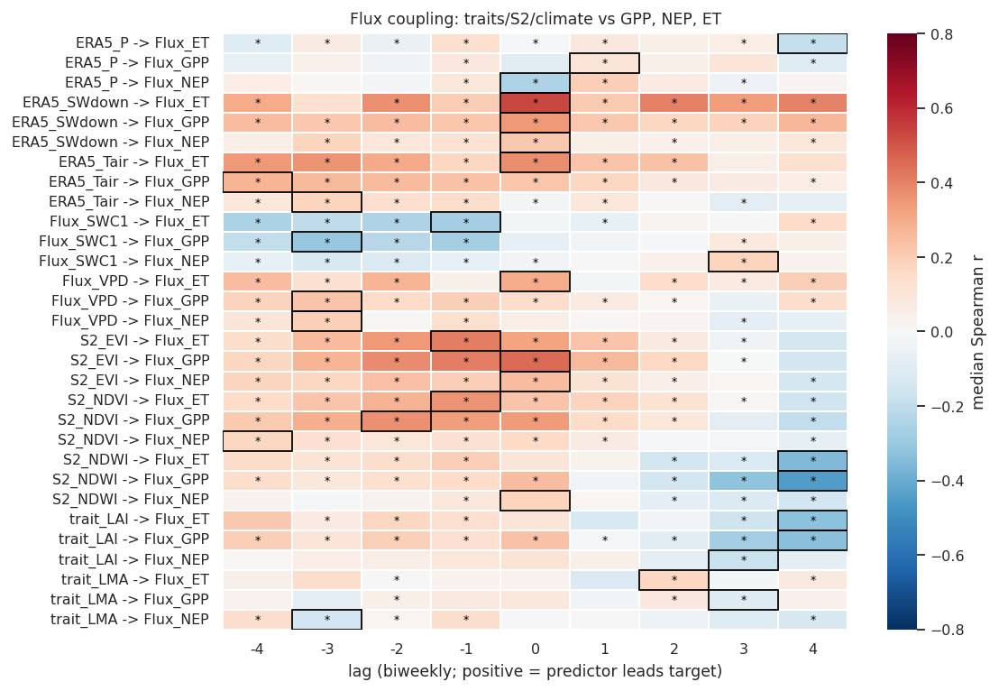

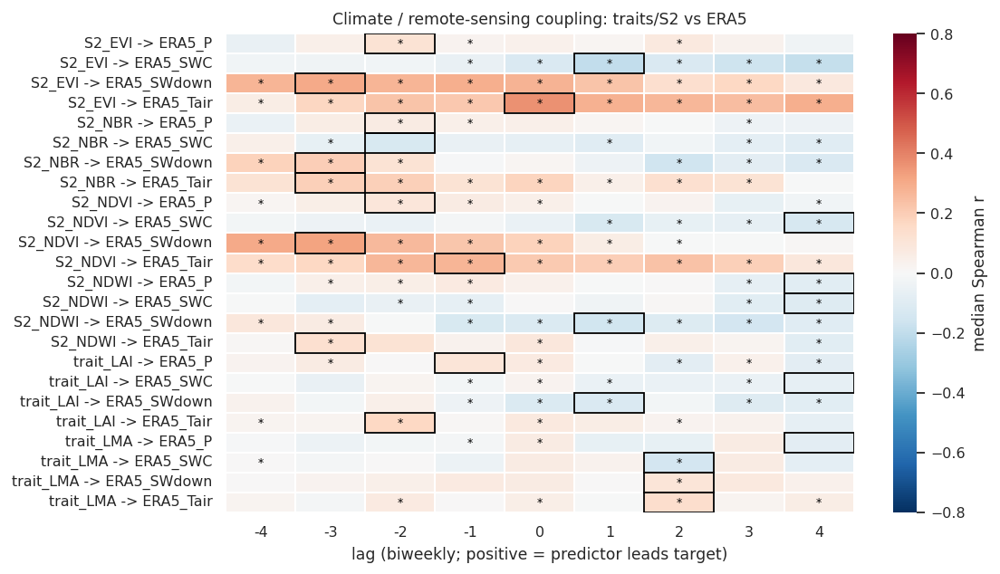

,analysis,site_id,pft_group,predictor,target,pair,lag,spearman_r,n,agg_boot_ci_low,agg_boot_ci_high,agg_boot_sig
0,flux_coupling,2,GRA,trait_LAI,Flux_GPP,trait_LAI -> Flux_GPP,-4,0.158442,21,0.086567,0.238149,True
1,flux_coupling,2,GRA,trait_LAI,Flux_GPP,trait_LAI -> Flux_GPP,-3,0.252400,22,0.062620,0.157506,True
2,flux_coupling,2,GRA,trait_LAI,Flux_GPP,trait_LAI -> Flux_GPP,-2,-0.188735,23,0.035617,0.185169,True
3,flux_coupling,2,GRA,trait_LAI,Flux_GPP,trait_LAI -> Flux_GPP,-1,0.317391,24,0.094718,0.200727,True
4,flux_coupling,2,GRA,trait_LAI,Flux_GPP,trait_LAI -> Flux_GPP,0,-0.163846,25,0.083789,0.301988,True
5,flux_coupling,2,GRA,trait_LAI,Flux_GPP,trait_LAI -> Flux_GPP,1,0.148696,24,0.015468,0.086060,True
6,flux_coupling,2,GRA,trait_LAI,Flux_GPP,trait_LAI -> Flux_GPP,2,-0.284585,23,-0.161886,-0.038980,True
7,flux_coupling,2,GRA,trait_LAI,Flux_GPP,trait_LAI -> Flux_GPP,3,-0.202710,22,-0.294548,-0.196952,True
8,flux_coupling,2,GRA,trait_LAI,Flux_GPP,trait_LAI -> Flux_GPP,4,0.149351,21,-0.274231,-0.154361,True
9,flux_coupling,2,GRA,trait_LMA,Flux_GPP,trait_LMA -> Flux_GPP,-4,-0.154545,21,-0.046781,0.064903,False


In [27]:
LAGS = np.arange(-4, 5)
BOOT_N = 10
BOOT_BLOCK = 4
MIN_N = 8
RNG = np.random.default_rng(42)

PREDICTOR_VARS = [
    "trait_LAI", "trait_LMA", "trait_N", "trait_Chl", "trait_Lignin",
    "S2_NDVI", "S2_EVI", "S2_NDWI",
    "Flux_VPD", "Flux_SWC1", "ERA5_Tair", "ERA5_P", "ERA5_SWdown",
]
FLUX_TARGETS = ["Flux_GPP", "Flux_NEP", "Flux_ET"]
CLIMATE_TARGETS = ["ERA5_Tair", "ERA5_SWC", "ERA5_P", "ERA5_SWdown"]
CLIMATE_PREDICTORS = [
    "trait_LAI", "trait_LMA", "trait_N", "trait_Chl", "trait_Lignin",
    "S2_NDVI", "S2_EVI", "S2_NDWI", "S2_NBR",
]

def finite_pair(x, y):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    mask = np.isfinite(x) & np.isfinite(y)
    return x[mask], y[mask]

def spearman_value(x, y):
    x, y = finite_pair(x, y)
    if len(x) < MIN_N or np.nanstd(x) == 0 or np.nanstd(y) == 0:
        return np.nan, len(x)
    rx = pd.Series(x).rank(method="average").to_numpy(dtype=float)
    ry = pd.Series(y).rank(method="average").to_numpy(dtype=float)
    if np.nanstd(rx) == 0 or np.nanstd(ry) == 0:
        return np.nan, len(x)
    return float(np.corrcoef(rx, ry)[0, 1]), len(x)

def lagged_vectors(frame, x_col, y_col, lag):
    sub = frame[["date", x_col, y_col]].sort_values("date")
    x = pd.to_numeric(sub[x_col], errors="coerce").to_numpy(dtype=float)
    y = pd.to_numeric(sub[y_col], errors="coerce").to_numpy(dtype=float)
    if lag > 0:
        return x[:-lag], y[lag:]
    if lag < 0:
        return x[-lag:], y[:lag]
    return x, y

def block_bootstrap_ci(x, y, n_boot=BOOT_N, block_size=BOOT_BLOCK):
    x, y = finite_pair(x, y)
    n = len(x)
    if n < MIN_N:
        return np.nan, np.nan, False
    values = []
    starts = np.arange(n)
    for _ in range(n_boot):
        idx = []
        while len(idx) < n:
            start = int(RNG.choice(starts))
            idx.extend([(start + j) % n for j in range(block_size)])
        idx = np.asarray(idx[:n])
        r, _ = spearman_value(x[idx], y[idx])
        if np.isfinite(r):
            values.append(r)
    if len(values) < max(20, n_boot // 4):
        return np.nan, np.nan, False
    lo, hi = np.nanpercentile(values, [2.5, 97.5])
    return float(lo), float(hi), bool((lo > 0) or (hi < 0))

def site_lag_records(data, predictors, targets, site_ids=None, label_prefix=""):
    rows = []
    if site_ids is None:
        site_ids = sorted(data["site_id"].dropna().astype(int).unique())
    for site_id in site_ids:
        site = data[data["site_id"].astype(int) == int(site_id)].copy()
        pft = site["pft_group"].dropna().iloc[0] if site["pft_group"].notna().any() else "unclassified"
        for target in targets:
            if target not in site.columns:
                continue
            for predictor in predictors:
                if predictor == target or predictor not in site.columns:
                    continue
                pair = f"{predictor} -> {target}"
                for lag in LAGS:
                    x, y = lagged_vectors(site, predictor, target, int(lag))
                    r, n = spearman_value(x, y)
                    rows.append({
                        "analysis": label_prefix,
                        "site_id": int(site_id),
                        "pft_group": pft,
                        "predictor": predictor,
                        "target": target,
                        "pair": pair,
                        "lag": int(lag),
                        "spearman_r": r,
                        "n": n,
                    })
    return pd.DataFrame(rows)

def aggregate_block_bootstrap(data, records, n_boot=BOOT_N, block_size=BOOT_BLOCK):
    rows = []
    site_cache = {int(site_id): site.sort_values("date") for site_id, site in data.groupby("site_id")}
    keys = records[["analysis", "predictor", "target", "pair", "lag"]].drop_duplicates()
    for rec in keys.itertuples(index=False):
        site_ids = records[
            (records["analysis"] == rec.analysis)
            & (records["predictor"] == rec.predictor)
            & (records["target"] == rec.target)
            & (records["lag"] == rec.lag)
        ]["site_id"].dropna().astype(int).unique()
        boot_values = []
        for _ in range(n_boot):
            bx_all, by_all = [], []
            for site_id in site_ids:
                site = site_cache.get(int(site_id))
                if site is None:
                    continue
                x, y = lagged_vectors(site, rec.predictor, rec.target, int(rec.lag))
                x, y = finite_pair(x, y)
                n = len(x)
                if n < MIN_N:
                    continue
                idx = []
                while len(idx) < n:
                    start = int(RNG.integers(0, n))
                    idx.extend([(start + j) % n for j in range(block_size)])
                idx = np.asarray(idx[:n])
                bx_all.append(x[idx])
                by_all.append(y[idx])
            if bx_all:
                r, n_total = spearman_value(np.concatenate(bx_all), np.concatenate(by_all))
                if np.isfinite(r):
                    boot_values.append(r)
        if len(boot_values) >= max(10, n_boot // 3):
            lo, hi = np.nanpercentile(boot_values, [2.5, 97.5])
            sig = bool((lo > 0) or (hi < 0))
        else:
            lo, hi, sig = np.nan, np.nan, False
        rows.append({
            "analysis": rec.analysis,
            "pair": rec.pair,
            "lag": int(rec.lag),
            "agg_boot_ci_low": float(lo) if np.isfinite(lo) else np.nan,
            "agg_boot_ci_high": float(hi) if np.isfinite(hi) else np.nan,
            "agg_boot_sig": sig,
        })
    return pd.DataFrame(rows)

flux_site_ids = sorted(analysis.loc[analysis["has_flux_values"].fillna(False), "site_id"].dropna().astype(int).unique())
trait_site_ids = sorted(analysis.loc[analysis["trait_LAI"].notna() | analysis["S2_NDVI"].notna(), "site_id"].dropna().astype(int).unique())

flux_lag = site_lag_records(analysis_diff, PREDICTOR_VARS, FLUX_TARGETS, site_ids=flux_site_ids, label_prefix="flux_coupling")
climate_lag = site_lag_records(analysis_diff, CLIMATE_PREDICTORS, CLIMATE_TARGETS, site_ids=trait_site_ids, label_prefix="climate_rs_coupling")
lag_results = pd.concat([flux_lag, climate_lag], ignore_index=True)
boot_summary = pd.concat(
    [
        aggregate_block_bootstrap(analysis_diff, flux_lag),
        aggregate_block_bootstrap(analysis_diff, climate_lag),
    ],
    ignore_index=True,
)
lag_results = lag_results.merge(boot_summary, on=["analysis", "pair", "lag"], how="left")
lag_path = TABLE_DIR / "lag_correlation_results_2022_diff_spearman_blockbootstrap.csv"
lag_results.to_csv(lag_path, index=False)
display(Markdown(f"Lag-correlation table written to `{lag_path}`"))

def aggregate_lag(records, group_name="All", bootstrap=None):
    agg = (
        records.groupby(["pair", "lag"], as_index=False)
        .agg(
            median_r=("spearman_r", "median"),
            n_sites=("spearman_r", lambda s: int(pd.to_numeric(s, errors="coerce").notna().sum())),
            median_n=("n", "median"),
        )
        .assign(group=group_name)
    )
    if bootstrap is not None and not bootstrap.empty:
        boot = bootstrap[["pair", "lag", "agg_boot_sig", "agg_boot_ci_low", "agg_boot_ci_high"]].drop_duplicates()
        agg = agg.merge(boot, on=["pair", "lag"], how="left")
    else:
        agg["agg_boot_sig"] = False
    return agg

def plot_lag_heatmap(records, title, min_sites=3, max_pairs=45, bootstrap=None):
    agg = aggregate_lag(records, bootstrap=bootstrap)
    keep_pairs = (
        agg.groupby("pair")["n_sites"].max()
        .sort_values(ascending=False)
        .head(max_pairs)
        .index
    )
    agg = agg[agg["pair"].isin(keep_pairs) & (agg["n_sites"] >= min_sites)].copy()
    if agg.empty:
        display(Markdown(f"No sufficient data for `{title}`."))
        return None
    mat = agg.pivot(index="pair", columns="lag", values="median_r").reindex(columns=LAGS)
    sig = agg.pivot(index="pair", columns="lag", values="agg_boot_sig").reindex(index=mat.index, columns=LAGS)
    fig_h = max(5.0, 0.22 * len(mat.index))
    fig, ax = plt.subplots(figsize=(8.6, fig_h))
    sns.heatmap(
        mat,
        ax=ax,
        cmap="RdBu_r",
        center=0,
        vmin=-0.8,
        vmax=0.8,
        linewidths=0.25,
        linecolor="white",
        cbar_kws={"label": "median Spearman r"},
    )
    for yi, pair in enumerate(mat.index):
        row = mat.loc[pair]
        if row.notna().any():
            best_lag = row.abs().idxmax()
            xi = list(mat.columns).index(best_lag)
            ax.add_patch(plt.Rectangle((xi, yi), 1, 1, fill=False, edgecolor="black", linewidth=1.0))
        for xi, lag in enumerate(mat.columns):
            frac = sig.loc[pair, lag] if pair in sig.index else np.nan
            if bool(frac):
                ax.text(xi + 0.5, yi + 0.5, "*", ha="center", va="center", color="black", fontsize=7)
    ax.set_title(title)
    ax.set_xlabel("lag (biweekly; positive = predictor leads target)")
    ax.set_ylabel("")
    plt.show()
    return fig

plot_lag_heatmap(
    flux_lag,
    "Flux coupling: traits/S2/climate vs GPP, NEP, ET",
    bootstrap=boot_summary[boot_summary["analysis"] == "flux_coupling"],
)
plot_lag_heatmap(
    climate_lag,
    "Climate / remote-sensing coupling: traits/S2 vs ERA5",
    bootstrap=boot_summary[boot_summary["analysis"] == "climate_rs_coupling"],
)

display(lag_results.head(20))


## Overview: best lag and robust lag stripes


Best-lag tables written to `/home/chaonan.ji/data/projects/ecospectra/docs/paper1_perspective/tables/fig3_all_sites_cap2000_flux_traits/best_lag_by_site_2022_diff_spearman.csv` and `/home/chaonan.ji/data/projects/ecospectra/docs/paper1_perspective/tables/fig3_all_sites_cap2000_flux_traits/best_lag_summary_2022_diff_spearman.csv`

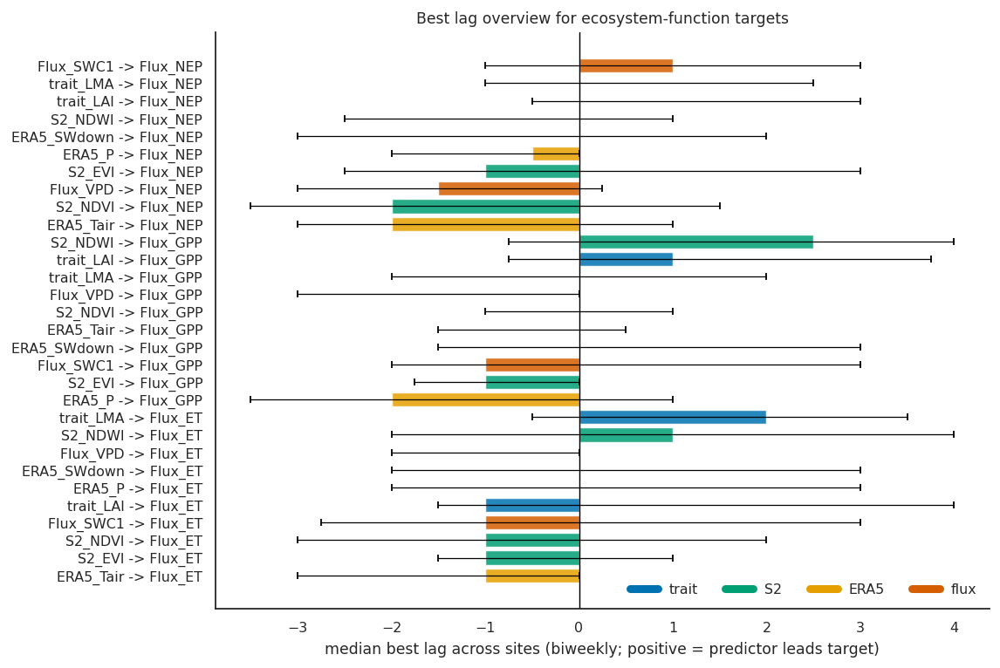

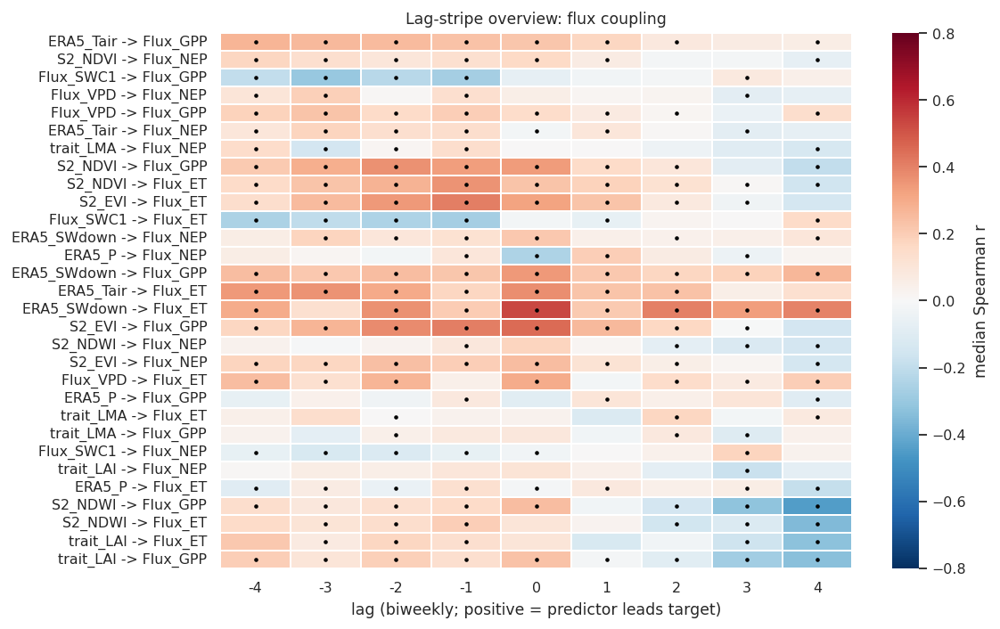

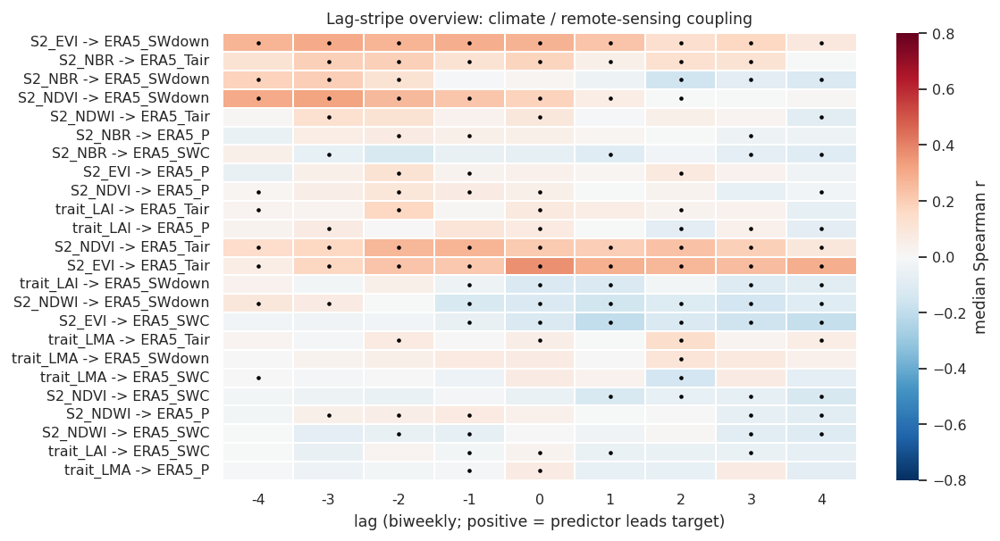

In [28]:
def variable_category(name):
    if name.startswith("trait_"):
        return "trait"
    if name.startswith("S2_"):
        return "S2"
    if name.startswith("ERA5_"):
        return "ERA5"
    if name.startswith("Flux_"):
        return "flux"
    return "other"

CATEGORY_COLORS = {"trait": "#0072B2", "S2": "#009E73", "ERA5": "#E69F00", "flux": "#D55E00", "other": "#777777"}

def best_lag_table(records, analysis_name="flux_coupling", min_n=MIN_N):
    sub = records[(records["analysis"] == analysis_name) & (records["n"] >= min_n)].copy()
    rows = []
    for (site_id, pair), grp in sub.groupby(["site_id", "pair"]):
        grp = grp.dropna(subset=["spearman_r"])
        if grp.empty:
            continue
        best = grp.loc[grp["spearman_r"].abs().idxmax()]
        rows.append({
            "site_id": int(site_id),
            "pair": pair,
            "predictor": best["predictor"],
            "target": best["target"],
            "best_lag": int(best["lag"]),
            "best_r": float(best["spearman_r"]),
            "category": variable_category(str(best["predictor"])),
        })
    out = pd.DataFrame(rows)
    if out.empty:
        return out
    summary = (
        out.groupby(["pair", "predictor", "target", "category"], as_index=False)
        .agg(
            median_best_lag=("best_lag", "median"),
            q25_best_lag=("best_lag", lambda s: float(np.nanpercentile(s, 25))),
            q75_best_lag=("best_lag", lambda s: float(np.nanpercentile(s, 75))),
            n_sites=("site_id", "nunique"),
            median_abs_best_r=("best_r", lambda s: float(np.nanmedian(np.abs(s)))),
        )
    )
    return out, summary

best_site_flux, best_summary_flux = best_lag_table(lag_results, "flux_coupling")
best_site_climate, best_summary_climate = best_lag_table(lag_results, "climate_rs_coupling")
best_site = pd.concat([best_site_flux.assign(analysis="flux_coupling"), best_site_climate.assign(analysis="climate_rs_coupling")], ignore_index=True)
best_summary = pd.concat([best_summary_flux.assign(analysis="flux_coupling"), best_summary_climate.assign(analysis="climate_rs_coupling")], ignore_index=True)
best_site_path = TABLE_DIR / "best_lag_by_site_2022_diff_spearman.csv"
best_summary_path = TABLE_DIR / "best_lag_summary_2022_diff_spearman.csv"
best_site.to_csv(best_site_path, index=False)
best_summary.to_csv(best_summary_path, index=False)

display(Markdown(f"Best-lag tables written to `{best_site_path}` and `{best_summary_path}`"))

plot_summary = (
    best_summary[best_summary["analysis"] == "flux_coupling"]
    .query("n_sites >= 3")
    .sort_values(["target", "median_best_lag", "category", "pair"])
)
plot_summary = plot_summary[plot_summary["target"].isin(["Flux_GPP", "Flux_NEP", "Flux_ET"])]
plot_summary = plot_summary.head(45)

fig_h = max(5.5, 0.22 * len(plot_summary))
fig, ax = plt.subplots(figsize=(8.8, fig_h))
y = np.arange(len(plot_summary))
x = plot_summary["median_best_lag"].to_numpy(dtype=float)
xerr = np.vstack([
    x - plot_summary["q25_best_lag"].to_numpy(dtype=float),
    plot_summary["q75_best_lag"].to_numpy(dtype=float) - x,
])
colors = plot_summary["category"].map(CATEGORY_COLORS).fillna("#777777").to_numpy()
ax.barh(y, x, color=colors, alpha=0.85)
ax.errorbar(x, y, xerr=xerr, fmt="none", ecolor="black", elinewidth=0.7, capsize=2)
ax.axvline(0, color="black", lw=0.8)
ax.set_yticks(y)
ax.set_yticklabels(plot_summary["pair"])
ax.set_xlabel("median best lag across sites (biweekly; positive = predictor leads target)")
ax.set_title("Best lag overview for ecosystem-function targets")
from matplotlib.lines import Line2D
handles = [Line2D([0], [0], color=color, lw=5, label=label) for label, color in CATEGORY_COLORS.items() if label != "other"]
ax.legend(handles=handles, frameon=False, ncol=4, loc="lower right")
plt.show()

def lag_stripe(records, title, analysis_name, max_pairs=45):
    sub = records[records["analysis"] == analysis_name].copy()
    agg = (
        sub.groupby(["pair", "predictor", "target", "lag"], as_index=False)
        .agg(
            median_r=("spearman_r", "median"),
            n_sites=("spearman_r", lambda s: int(pd.to_numeric(s, errors="coerce").notna().sum())),
            sig=("agg_boot_sig", "max"),
        )
    )
    keep = (
        agg.groupby("pair")["n_sites"].max()
        .sort_values(ascending=False)
        .head(max_pairs)
        .index
    )
    agg = agg[agg["pair"].isin(keep)].copy()
    order = (
        agg.groupby("pair")
        .apply(lambda d: d.loc[d["median_r"].abs().idxmax(), "lag"] if d["median_r"].notna().any() else 999, include_groups=False)
        .sort_values()
        .index
    )
    mat = agg.pivot(index="pair", columns="lag", values="median_r").reindex(index=order, columns=LAGS)
    sig = agg.pivot(index="pair", columns="lag", values="sig").reindex(index=order, columns=LAGS)
    fig_h = max(5.0, 0.20 * len(mat.index))
    fig, ax = plt.subplots(figsize=(8.8, fig_h))
    sns.heatmap(
        mat,
        ax=ax,
        cmap="RdBu_r",
        center=0,
        vmin=-0.8,
        vmax=0.8,
        linewidths=0.25,
        linecolor="white",
        cbar_kws={"label": "median Spearman r"},
    )
    for yi, pair in enumerate(mat.index):
        for xi, lag in enumerate(mat.columns):
            if bool(sig.loc[pair, lag]):
                ax.scatter(xi + 0.5, yi + 0.5, s=12, color="black", marker=".")
    ax.set_title(title)
    ax.set_xlabel("lag (biweekly; positive = predictor leads target)")
    ax.set_ylabel("")
    plt.show()

lag_stripe(lag_results, "Lag-stripe overview: flux coupling", "flux_coupling", max_pairs=45)
lag_stripe(lag_results, "Lag-stripe overview: climate / remote-sensing coupling", "climate_rs_coupling", max_pairs=45)


## PFT-grouped lag-correlation heatmaps


,pft_group,n_flux_sites
0,ENF,8
1,CRO,3
2,GRA,3
3,DBF,2
4,MF,2
5,EBF,1
6,OSH,1
7,SAV,1
8,WET,1


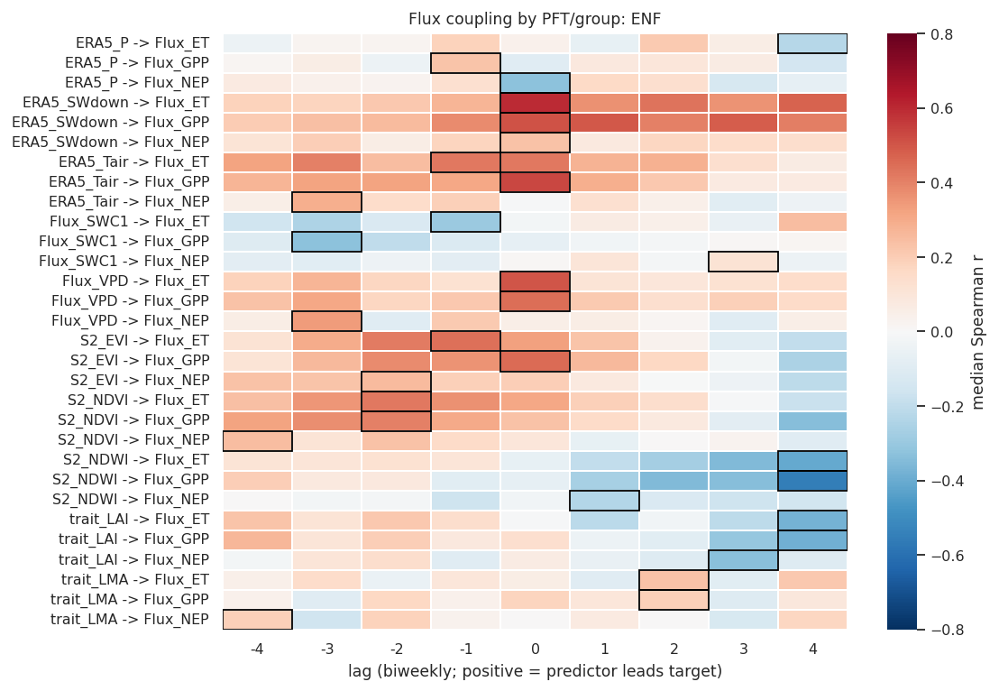

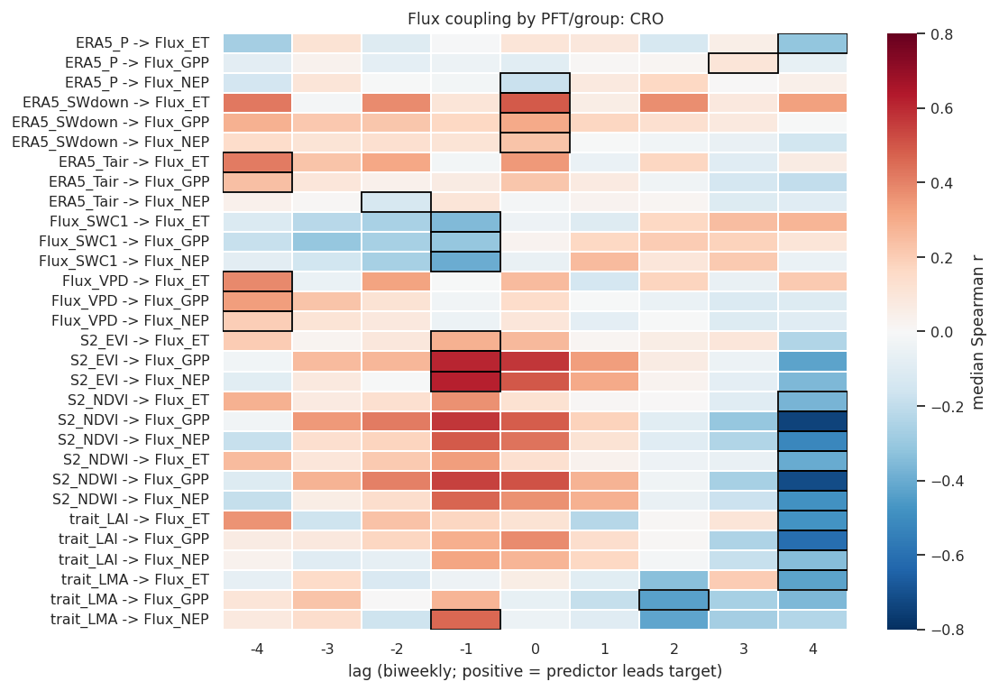

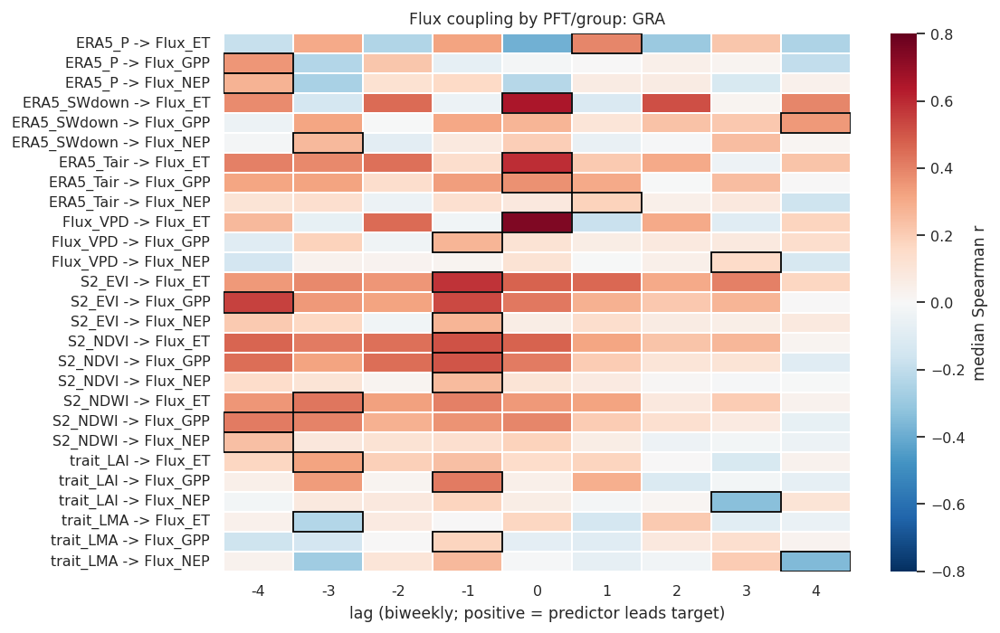

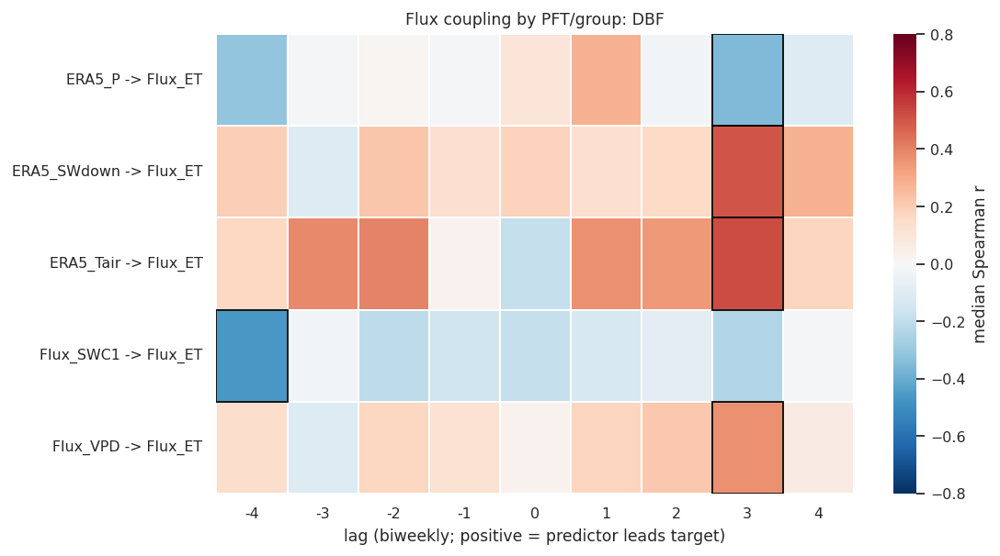

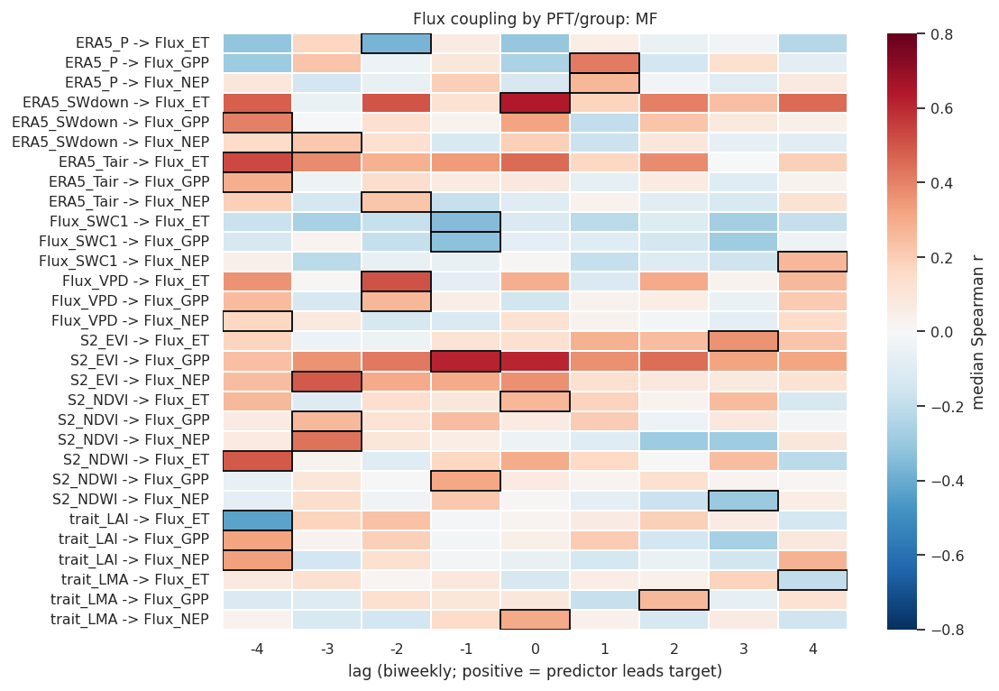

In [29]:
pft_counts = (
    analysis[analysis["site_id"].isin(flux_site_ids)]
    [["site_id", "pft_group"]]
    .drop_duplicates()
    .groupby("pft_group")
    .size()
    .sort_values(ascending=False)
)
display(pft_counts.rename("n_flux_sites").reset_index())

groups_to_plot = pft_counts[pft_counts >= 2].index.tolist()
if not groups_to_plot:
    display(Markdown("No PFT group has at least two flux sites; only the all-site heatmap is interpretable."))
else:
    for group in groups_to_plot:
        sub = flux_lag[flux_lag["pft_group"] == group].copy()
        plot_lag_heatmap(sub, f"Flux coupling by PFT/group: {group}", min_sites=2, max_pairs=35)


## CCF small multiples for key pairs


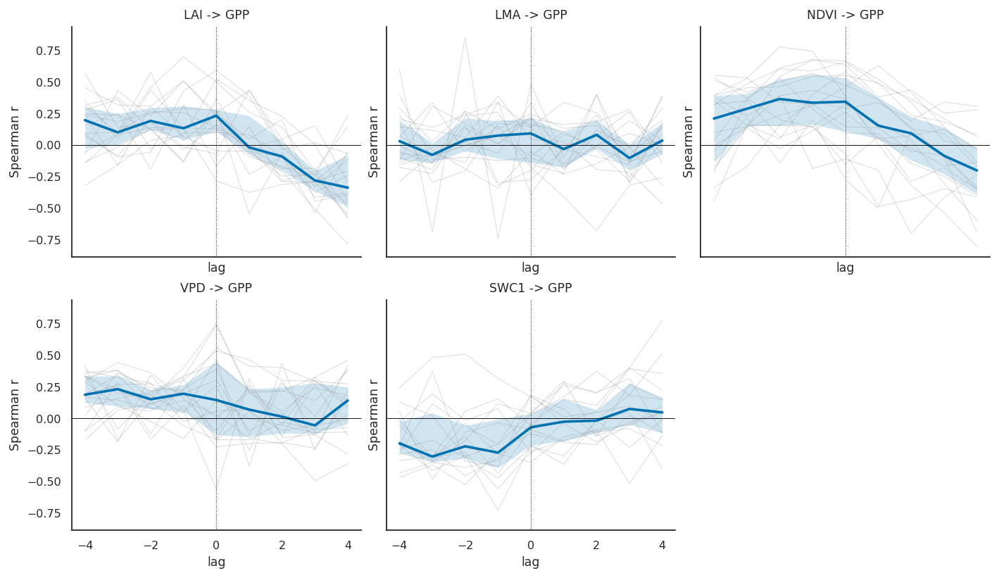

CCF key-pair table written to `/home/chaonan.ji/data/projects/ecospectra/docs/paper1_perspective/tables/fig3_all_sites_cap2000_flux_traits/ccf_key_pairs_2022_diff_spearman.csv`

In [30]:
KEY_PAIRS = [
    ("trait_LAI", "Flux_GPP", "LAI -> GPP"),
    ("trait_LMA", "Flux_GPP", "LMA -> GPP"),
    ("S2_NDVI", "Flux_GPP", "NDVI -> GPP"),
    ("Flux_VPD", "Flux_GPP", "VPD -> GPP"),
    ("Flux_SWC1", "Flux_GPP", "SWC1 -> GPP"),
]

fig, axes = plt.subplots(2, 3, figsize=(10.8, 6.2), sharex=True, sharey=True, constrained_layout=True)
axes = axes.ravel()
ccf_rows = []
for ax, (predictor, target, label) in zip(axes, KEY_PAIRS, strict=False):
    site_curves = []
    for site_id in flux_site_ids:
        site = analysis_diff[analysis_diff["site_id"].astype(int) == int(site_id)].copy()
        rs = []
        for lag in LAGS:
            x, y = lagged_vectors(site, predictor, target, int(lag))
            r, n = spearman_value(x, y)
            rs.append(r)
            ccf_rows.append({"site_id": site_id, "predictor": predictor, "target": target, "label": label, "lag": int(lag), "spearman_r": r, "n": n})
        if np.isfinite(rs).any():
            ax.plot(LAGS, rs, color="#9aa0a6", lw=0.6, alpha=0.35)
            site_curves.append(rs)
    curves = np.asarray(site_curves, dtype=float)
    if curves.size:
        med = np.nanmedian(curves, axis=0)
        q25 = np.nanpercentile(curves, 25, axis=0)
        q75 = np.nanpercentile(curves, 75, axis=0)
        ax.plot(LAGS, med, color="#0072B2", lw=2.0)
        ax.fill_between(LAGS, q25, q75, color="#0072B2", alpha=0.18, linewidth=0)
    ax.axhline(0, color="black", lw=0.5)
    ax.axvline(0, color="black", lw=0.5, ls=":")
    ax.set_title(label)
    ax.set_xlabel("lag")
    ax.set_ylabel("Spearman r")
axes[-1].axis("off")
plt.show()

ccf_df = pd.DataFrame(ccf_rows)
ccf_path = TABLE_DIR / "ccf_key_pairs_2022_diff_spearman.csv"
ccf_df.to_csv(ccf_path, index=False)
display(Markdown(f"CCF key-pair table written to `{ccf_path}`"))


## Seasonal phase polar plot


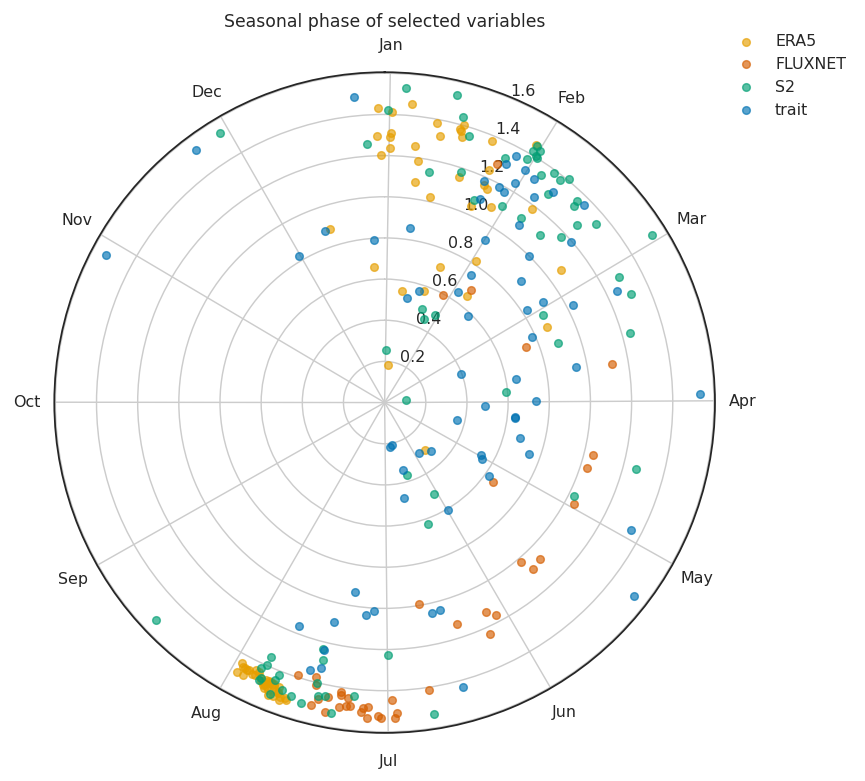

Seasonal phase table written to `/home/chaonan.ji/data/projects/ecospectra/docs/paper1_perspective/tables/fig3_all_sites_cap2000_flux_traits/seasonal_phase_fit_2022.csv`

,site_id,variable,category,amplitude,peak_doy
0,0,trait_LAI,trait,1.081616,37.604523
1,0,trait_LMA,trait,0.605220,151.737727
2,0,S2_NDVI,S2,1.431315,188.590992
3,0,S2_NDWI,S2,1.234440,196.801908
4,0,ERA5_Tair,ERA5,1.502528,203.153497
5,0,ERA5_SWC,ERA5,1.081024,28.853348
6,2,trait_LAI,trait,1.238682,196.680169
7,2,trait_LMA,trait,0.735901,90.575639
8,2,S2_NDVI,S2,1.530022,192.586809
9,2,S2_NDWI,S2,1.455865,194.288372


In [31]:
PHASE_VARS = {
    "trait_LAI": "trait",
    "trait_LMA": "trait",
    "S2_NDVI": "S2",
    "S2_NDWI": "S2",
    "ERA5_Tair": "ERA5",
    "ERA5_SWC": "ERA5",
    "Flux_GPP": "FLUXNET",
    "Flux_ET": "FLUXNET",
}
PHASE_COLORS = {"trait": "#0072B2", "S2": "#009E73", "ERA5": "#E69F00", "FLUXNET": "#D55E00"}

def fit_phase(dates, values):
    sub = pd.DataFrame({"date": pd.to_datetime(dates), "value": pd.to_numeric(values, errors="coerce")}).dropna()
    sub = sub[sub["date"].dt.dayofyear.between(30, 330)].copy()
    if len(sub) < 10 or sub["value"].std() == 0:
        return np.nan, np.nan
    t = sub["date"].dt.dayofyear.to_numpy(dtype=float)
    y = sub["value"].to_numpy(dtype=float)
    y = (y - np.nanmean(y)) / np.nanstd(y)
    def model(t, amp, phi, offset):
        return amp * np.sin(2 * np.pi * t / 365.25 + phi) + offset
    try:
        popt, _ = curve_fit(model, t, y, p0=[1.0, 0.0, 0.0], maxfev=10000)
    except Exception:
        return np.nan, np.nan
    amp, phi, _offset = popt
    peak_doy = ((np.pi / 2 - phi) * 365.25 / (2 * np.pi)) % 365.25
    return float(abs(amp)), float(peak_doy)

phase_rows = []
for site_id, site in analysis.groupby("site_id"):
    for var, category in PHASE_VARS.items():
        if var not in site.columns:
            continue
        amp, peak_doy = fit_phase(site["date"], site[var])
        if np.isfinite(amp) and np.isfinite(peak_doy):
            phase_rows.append({"site_id": int(site_id), "variable": var, "category": category, "amplitude": amp, "peak_doy": peak_doy})
phase_df = pd.DataFrame(phase_rows)
phase_path = TABLE_DIR / "seasonal_phase_fit_2022.csv"
phase_df.to_csv(phase_path, index=False)

fig = plt.figure(figsize=(7.2, 6.6))
ax = fig.add_subplot(111, projection="polar")
for category, sub in phase_df.groupby("category"):
    theta = 2 * np.pi * sub["peak_doy"].to_numpy(dtype=float) / 365.25
    radius = sub["amplitude"].clip(upper=np.nanpercentile(phase_df["amplitude"], 95))
    ax.scatter(theta, radius, s=18, alpha=0.65, color=PHASE_COLORS.get(category, "grey"), label=category)
ax.set_theta_zero_location("N")
ax.set_theta_direction(-1)
month_doys = np.array([1, 32, 60, 91, 121, 152, 182, 213, 244, 274, 305, 335])
ax.set_xticks(2 * np.pi * month_doys / 365.25)
ax.set_xticklabels(["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_title("Seasonal phase of selected variables")
ax.legend(frameon=False, loc="upper right", bbox_to_anchor=(1.22, 1.08))
plt.show()

display(Markdown(f"Seasonal phase table written to `{phase_path}`"))
display(phase_df.head(20))


## Phase overview strip plot


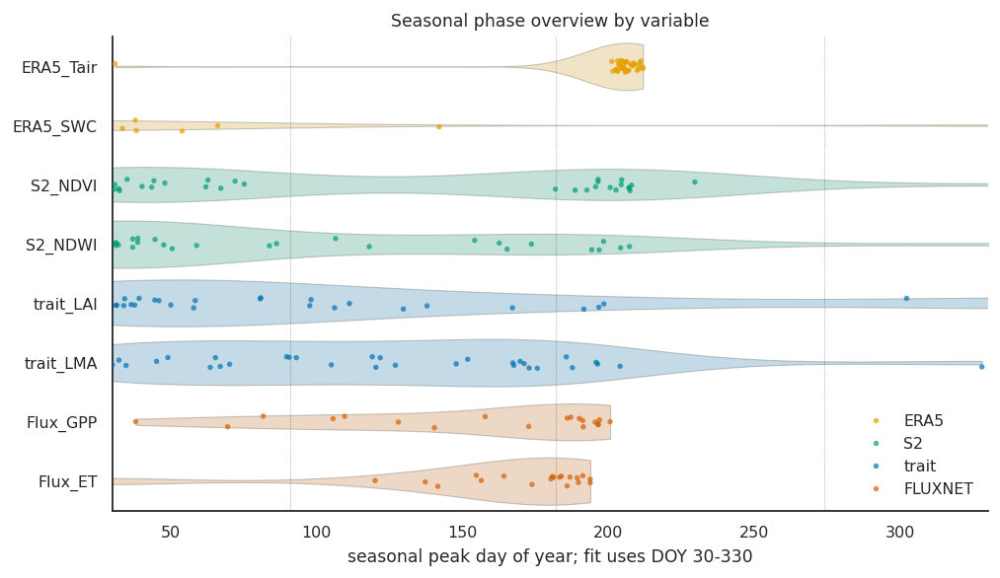

In [32]:
phase_order = [
    "ERA5_Tair", "ERA5_SWC", "S2_NDVI", "S2_NDWI",
    "trait_LAI", "trait_LMA", "Flux_GPP", "Flux_ET",
]
phase_plot = phase_df.copy()
phase_plot["variable"] = pd.Categorical(phase_plot["variable"], categories=phase_order, ordered=True)
phase_plot = phase_plot.dropna(subset=["variable"]).sort_values("variable")

fig, ax = plt.subplots(figsize=(8.8, 4.8))
sns.violinplot(
    data=phase_plot,
    x="peak_doy",
    y="variable",
    hue="category",
    dodge=False,
    inner=None,
    cut=0,
    linewidth=0.6,
    palette=PHASE_COLORS,
    alpha=0.25,
    ax=ax,
)
sns.stripplot(
    data=phase_plot,
    x="peak_doy",
    y="variable",
    hue="category",
    dodge=False,
    size=3.0,
    alpha=0.70,
    palette=PHASE_COLORS,
    ax=ax,
)
handles, labels = ax.get_legend_handles_labels()
dedup = dict(zip(labels, handles))
ax.legend(dedup.values(), dedup.keys(), frameon=False, loc="lower right")
ax.set_xlim(30, 330)
ax.set_xlabel("seasonal peak day of year; fit uses DOY 30-330")
ax.set_ylabel("")
ax.set_title("Seasonal phase overview by variable")
for doy in [91, 182, 274]:
    ax.axvline(doy, color="black", lw=0.4, ls=":", alpha=0.5)
plt.show()


## Supplementary cluster heatmap


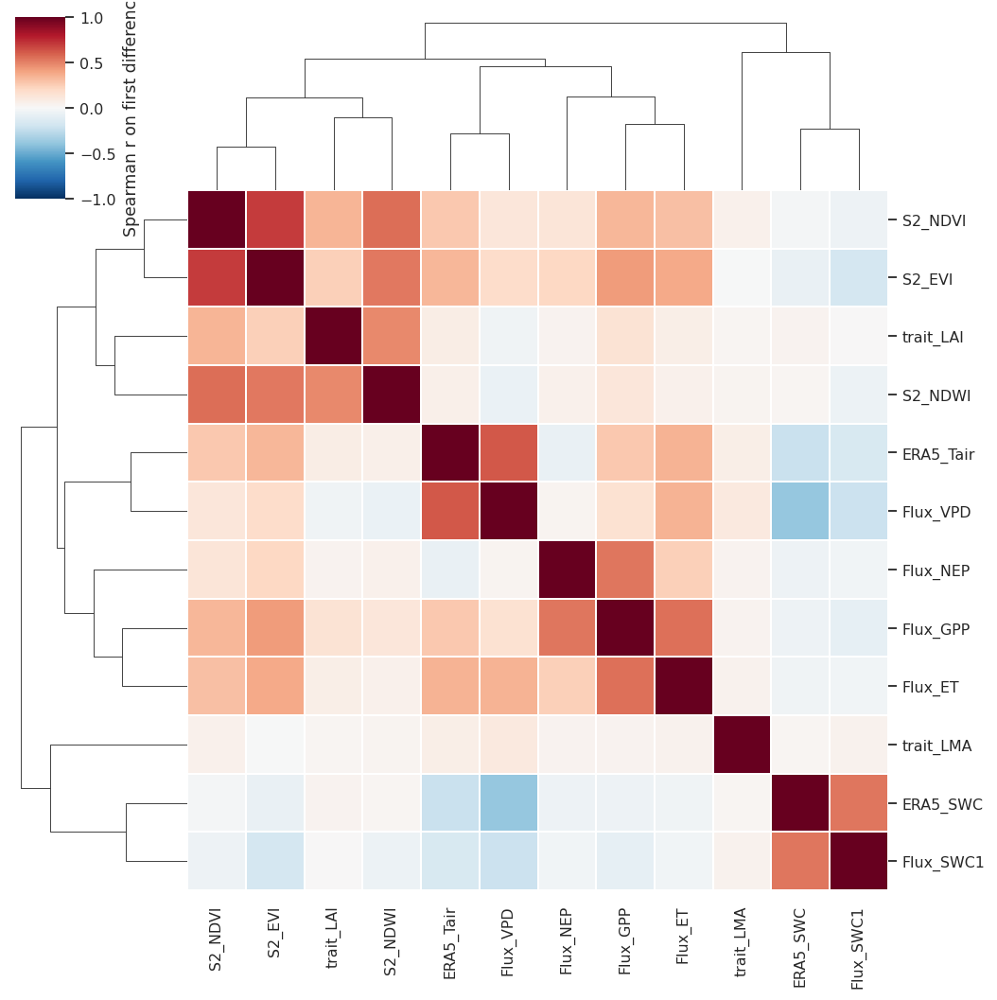

Cluster correlation matrix written to `/home/chaonan.ji/data/projects/ecospectra/docs/paper1_perspective/tables/fig3_all_sites_cap2000_flux_traits/cluster_variable_correlation_2022_diff_spearman.csv`

In [33]:
cluster_vars = [
    "trait_LAI", "trait_LMA", "trait_N", "trait_Chl", "trait_Lignin",
    "S2_NDVI", "S2_EVI", "S2_NDWI", "ERA5_Tair", "ERA5_SWC",
    "Flux_GPP", "Flux_NEP", "Flux_ET", "Flux_VPD", "Flux_SWC1",
]
cluster_vars = [col for col in cluster_vars if col in analysis_diff.columns]
cluster_data = analysis_diff[cluster_vars].apply(pd.to_numeric, errors="coerce")
valid_cols = [c for c in cluster_vars if cluster_data[c].notna().sum() >= 20]
if len(valid_cols) >= 4:
    corr = cluster_data[valid_cols].corr(method="spearman", min_periods=20)
    cg = sns.clustermap(
        corr,
        cmap="RdBu_r",
        center=0,
        vmin=-1,
        vmax=1,
        linewidths=0.25,
        figsize=(8.2, 8.2),
        cbar_kws={"label": "Spearman r on first differences"},
    )
    plt.show()
    corr_path = TABLE_DIR / "cluster_variable_correlation_2022_diff_spearman.csv"
    corr.to_csv(corr_path)
    display(Markdown(f"Cluster correlation matrix written to `{corr_path}`"))
else:
    display(Markdown("Not enough variables with sufficient data for a cluster heatmap."))


## Optional Granger screen


In [34]:
try:
    from statsmodels.tsa.stattools import grangercausalitytests
except Exception as exc:
    display(Markdown(f"`statsmodels` unavailable; Granger screen skipped: `{exc}`"))
else:
    granger_pairs = [
        ("trait_LAI", "Flux_GPP"),
        ("trait_LMA", "Flux_GPP"),
        ("S2_NDVI", "Flux_GPP"),
        ("Flux_VPD", "Flux_GPP"),
        ("Flux_SWC1", "Flux_GPP"),
    ]
    rows = []
    for site_id in flux_site_ids:
        site = analysis[analysis["site_id"].astype(int) == int(site_id)].sort_values("date")
        for cause, effect in granger_pairs:
            sub = site[[effect, cause]].apply(pd.to_numeric, errors="coerce").diff().dropna()
            if len(sub) < 12 or sub.nunique().min() <= 1:
                continue
            try:
                res = grangercausalitytests(sub[[effect, cause]], maxlag=2, verbose=False)
                pvals = [res[lag][0]["ssr_ftest"][1] for lag in res]
                rows.append({"site_id": int(site_id), "cause": cause, "effect": effect, "min_p": float(np.nanmin(pvals)), "best_lag": int(np.nanargmin(pvals) + 1), "n": len(sub)})
            except Exception:
                continue
    granger = pd.DataFrame(rows)
    if granger.empty:
        display(Markdown("No Granger tests had enough valid data."))
    else:
        granger["neg_log10_p"] = -np.log10(granger["min_p"].clip(lower=1e-12))
        granger_path = TABLE_DIR / "granger_key_pairs_screen_2022_diff.csv"
        granger.to_csv(granger_path, index=False)
        summary = granger.groupby(["cause", "effect"], as_index=False).agg(
            n_sites=("site_id", "nunique"),
            median_neg_log10_p=("neg_log10_p", "median"),
            frac_p_lt_0p05=("min_p", lambda s: float((s < 0.05).mean())),
        )
        display(Markdown(f"Granger screen table written to `{granger_path}`"))
        display(summary)


/opt/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/stattools.py:1556: FutureWarning: verbose is deprecated since functions should not print results
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/stattools.py:1556: FutureWarning: verbose is deprecated since functions should not print results
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/stattools.py:1556: FutureWarning: verbose is deprecated since functions should not print results
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/stattools.py:1556: FutureWarning: verbose is deprecated since functions should not print results
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/stattools.py:1556: FutureWarning: verbose is deprecated since functions should not print results
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/stattools.py:1556: FutureWarning: verbose is deprecated since function

Granger screen table written to `/home/chaonan.ji/data/projects/ecospectra/docs/paper1_perspective/tables/fig3_all_sites_cap2000_flux_traits/granger_key_pairs_screen_2022_diff.csv`

,cause,effect,n_sites,median_neg_log10_p,frac_p_lt_0p05
0,Flux_SWC1,Flux_GPP,16,0.386613,0.062500
1,Flux_VPD,Flux_GPP,19,0.489938,0.052632
2,S2_NDVI,Flux_GPP,18,0.378608,0.055556
3,trait_LAI,Flux_GPP,18,0.450053,0.166667
4,trait_LMA,Flux_GPP,18,0.290562,0.000000


## Browse site figures


### site 44

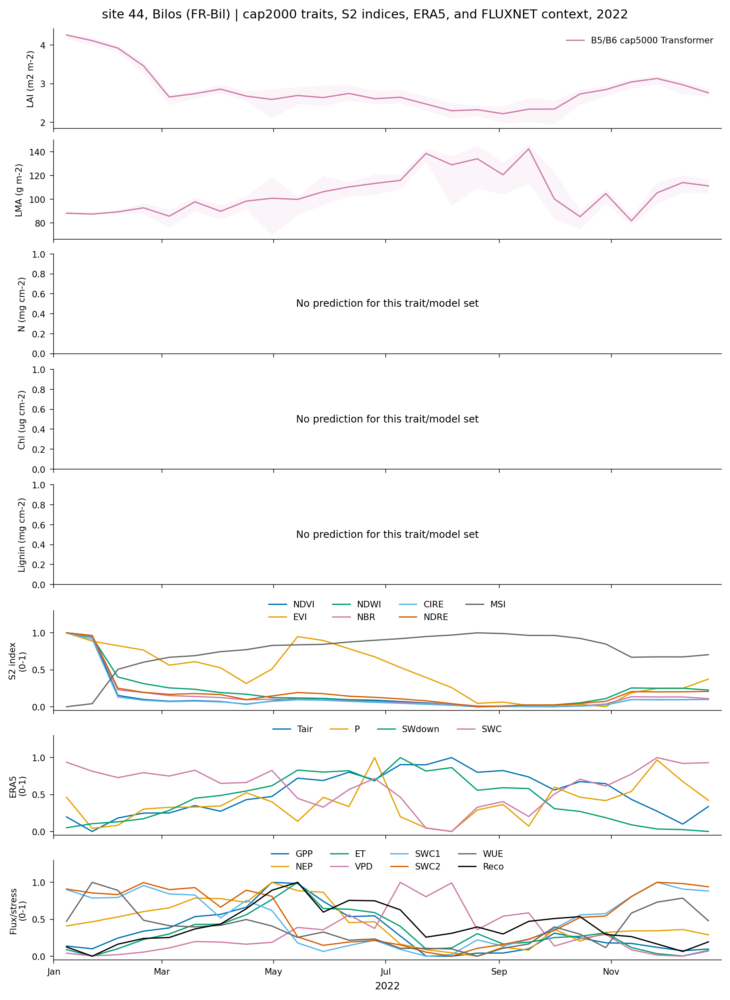

In [35]:
site_id = 44
image_path = FIG_DIR / f"site_{site_id:02d}_cap2000_traits_flux_2022.png"
display(Markdown(f"### site {site_id}"))
display(Image(filename=str(image_path)))


### site 0

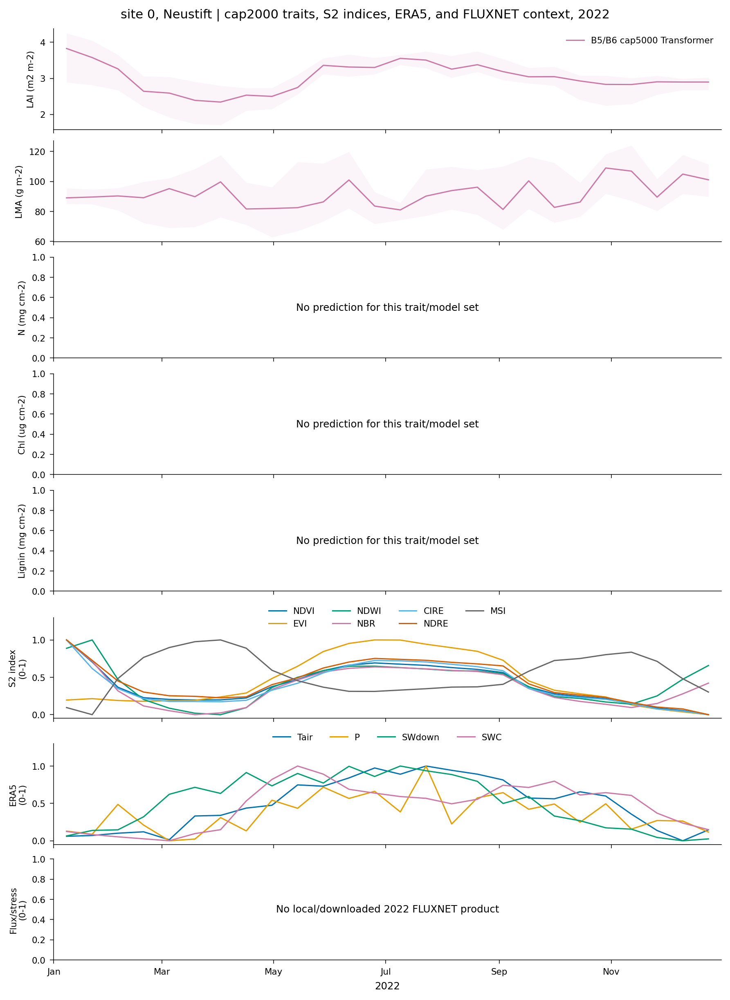

### site 2

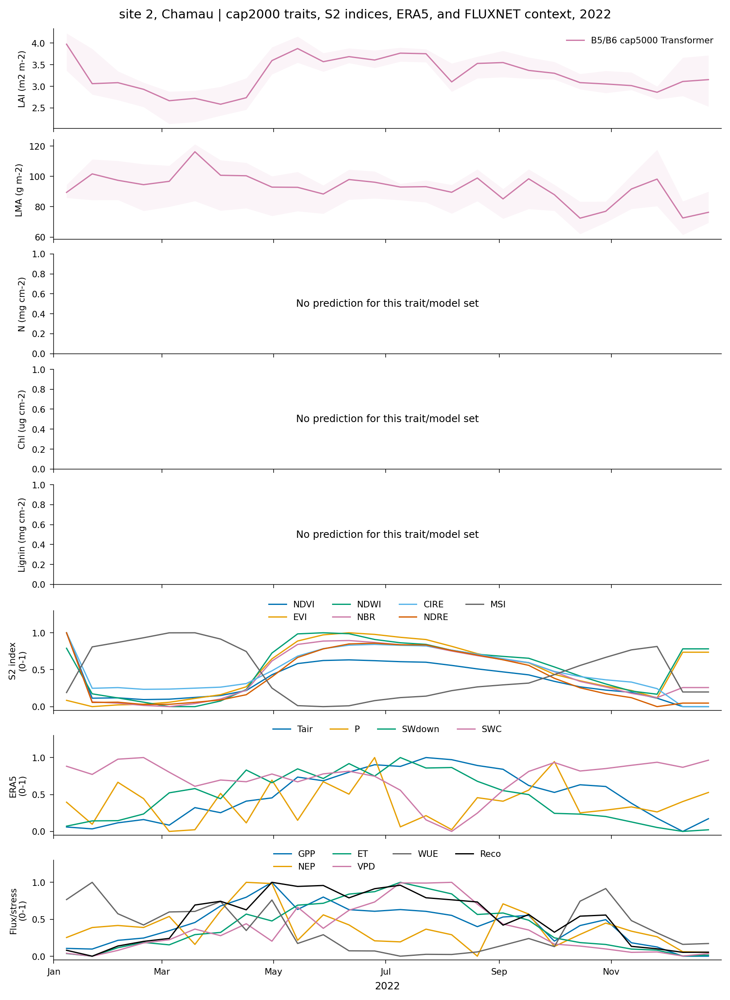

### site 3

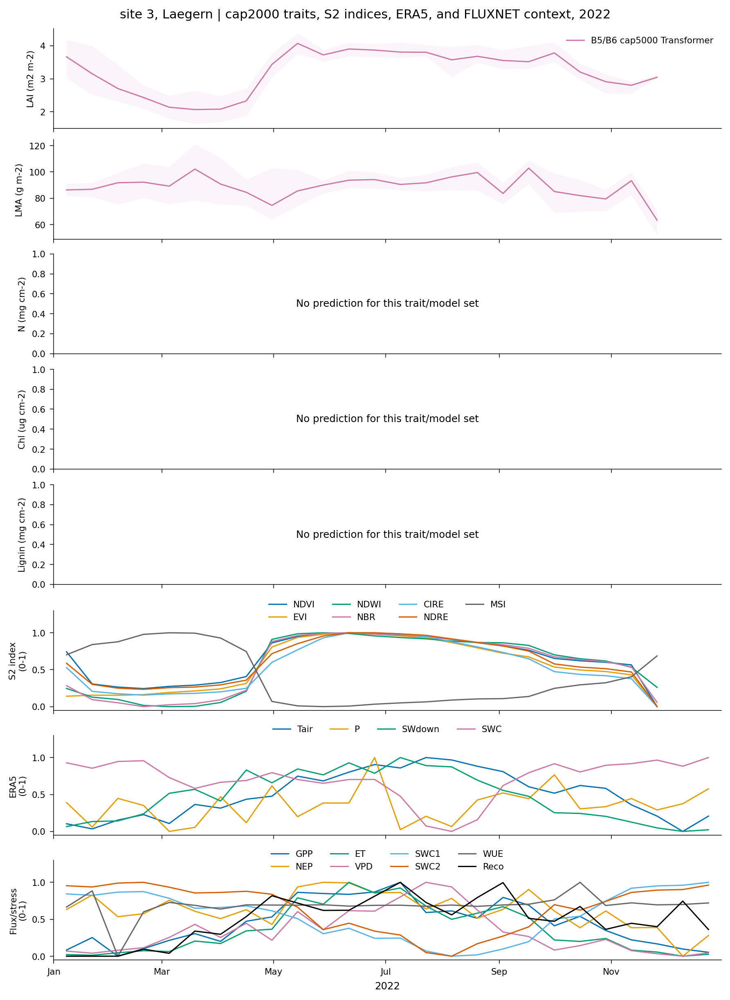

### site 6

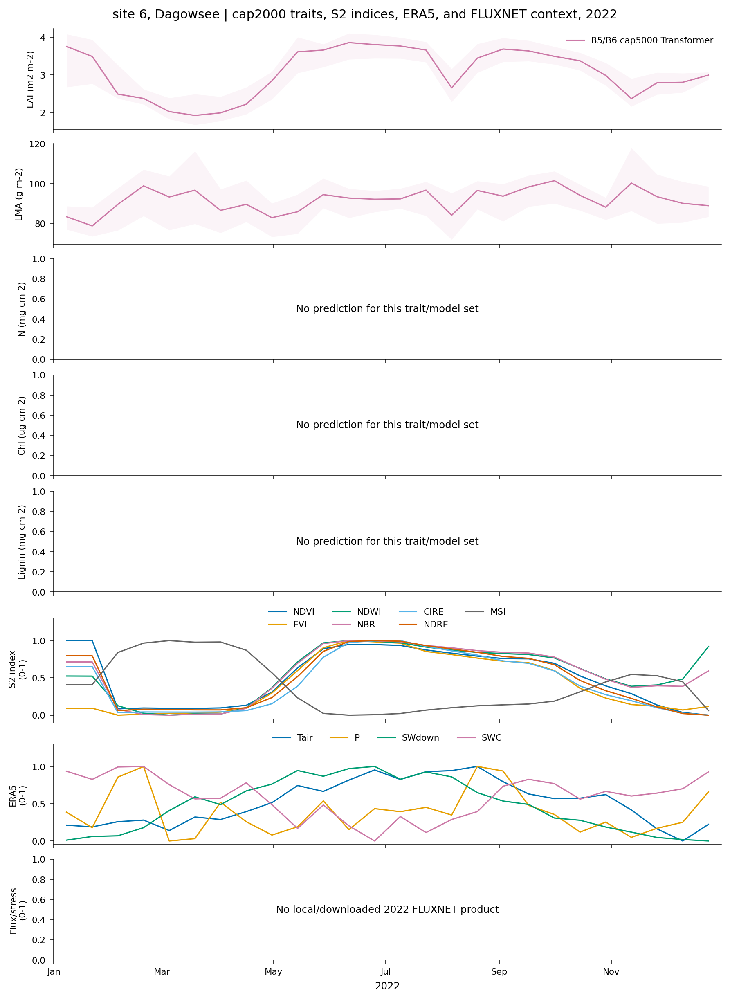

### site 7

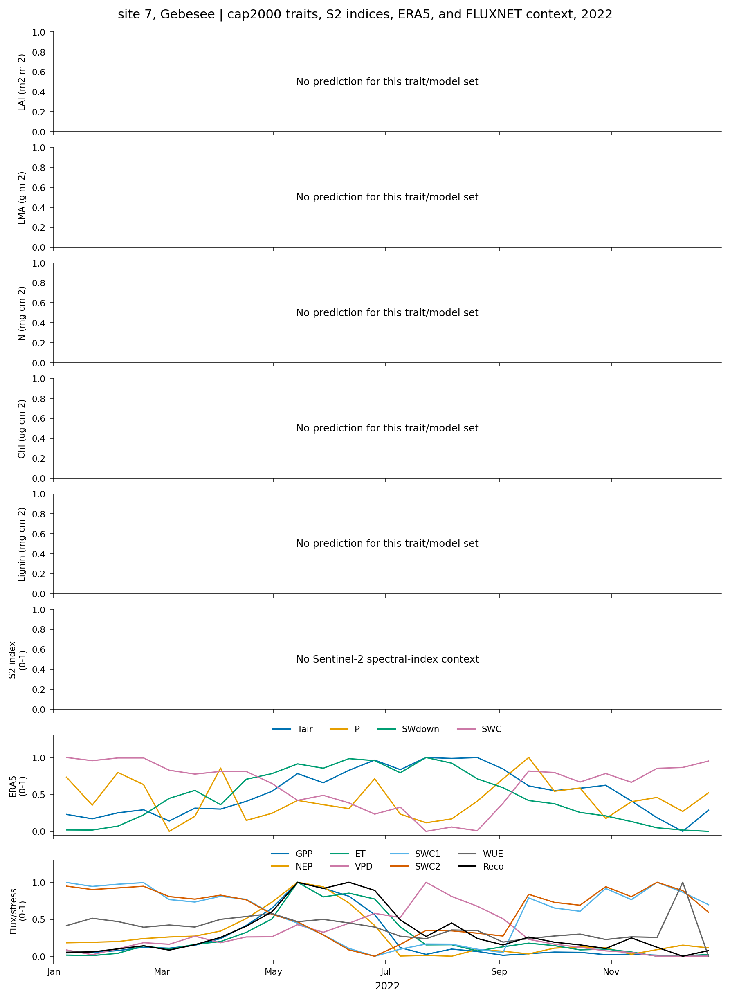

### site 9

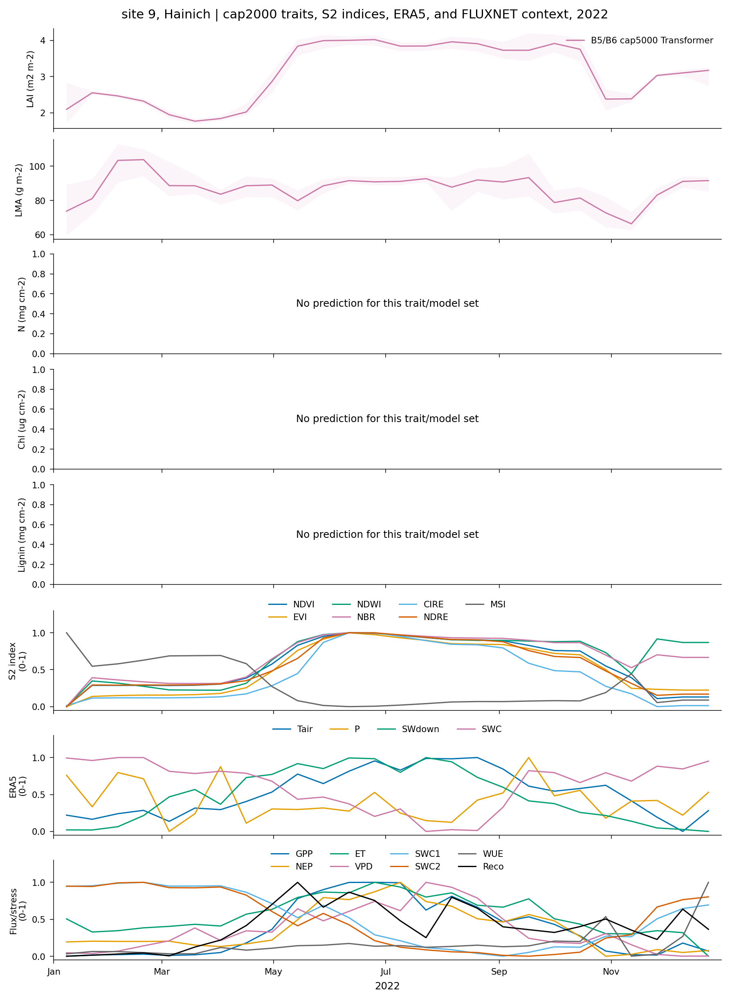

### site 10

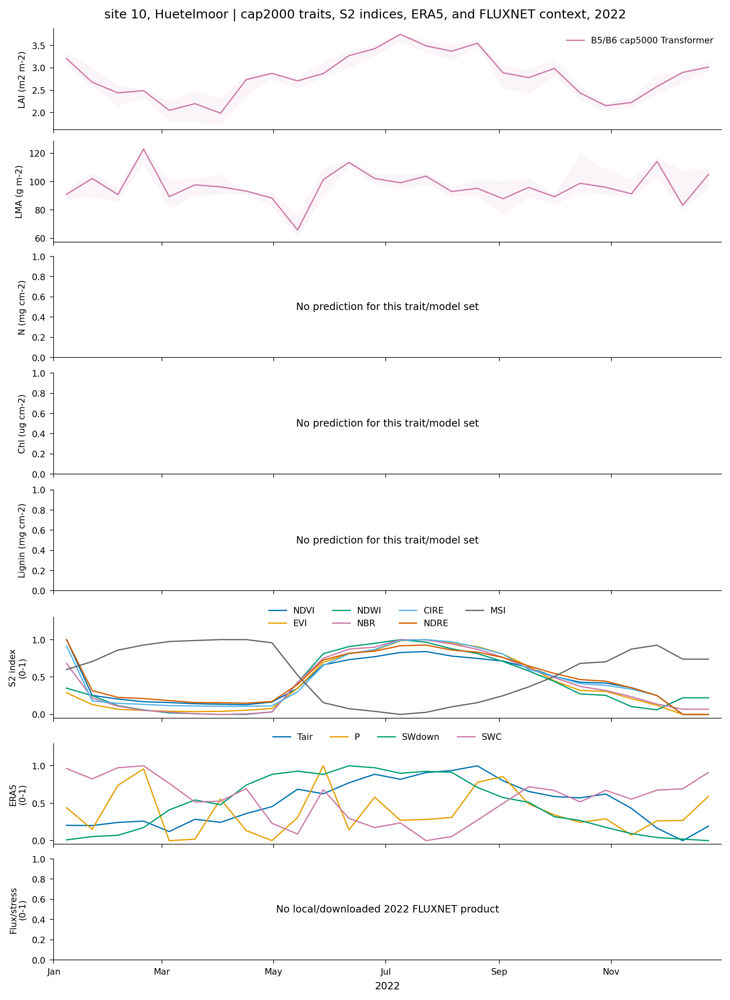

### site 11

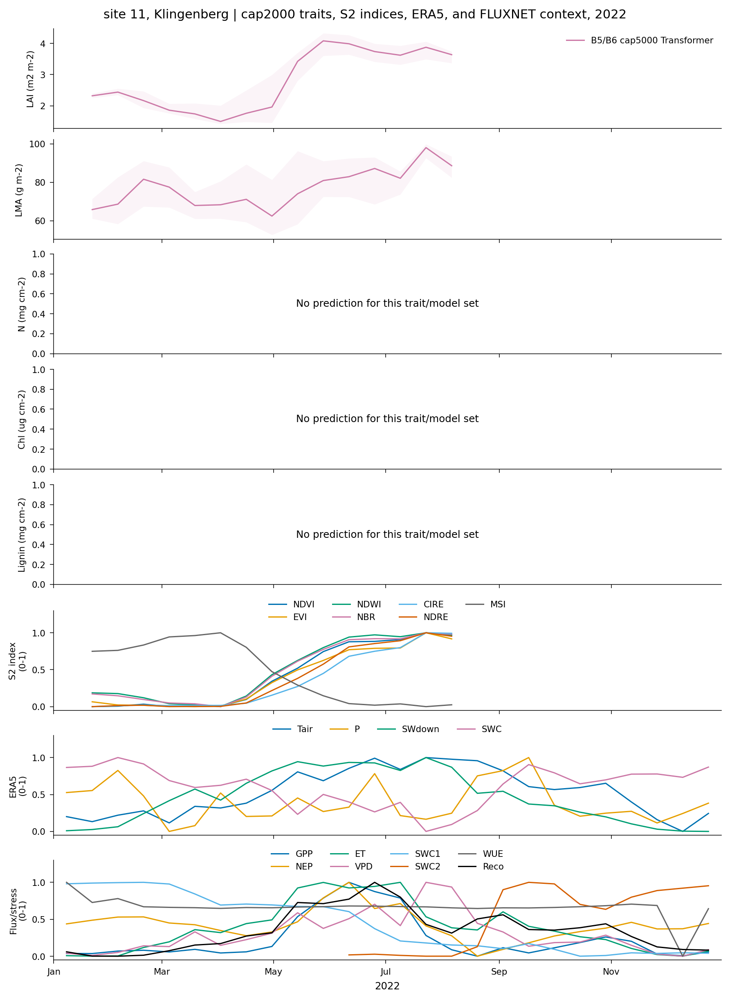

### site 13

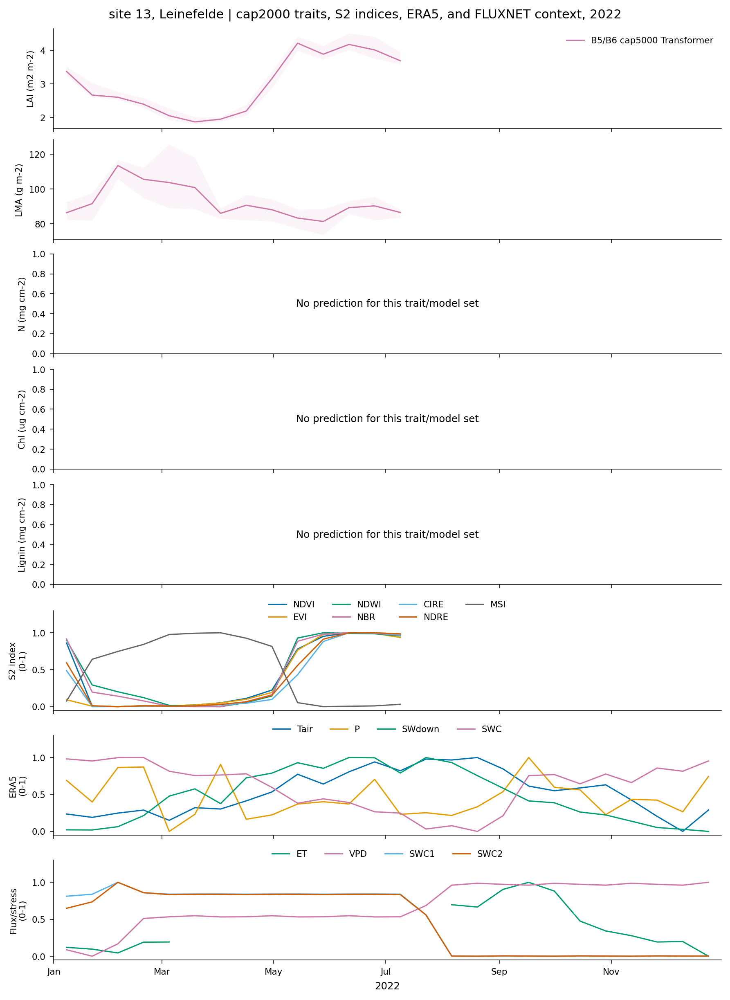

### site 15

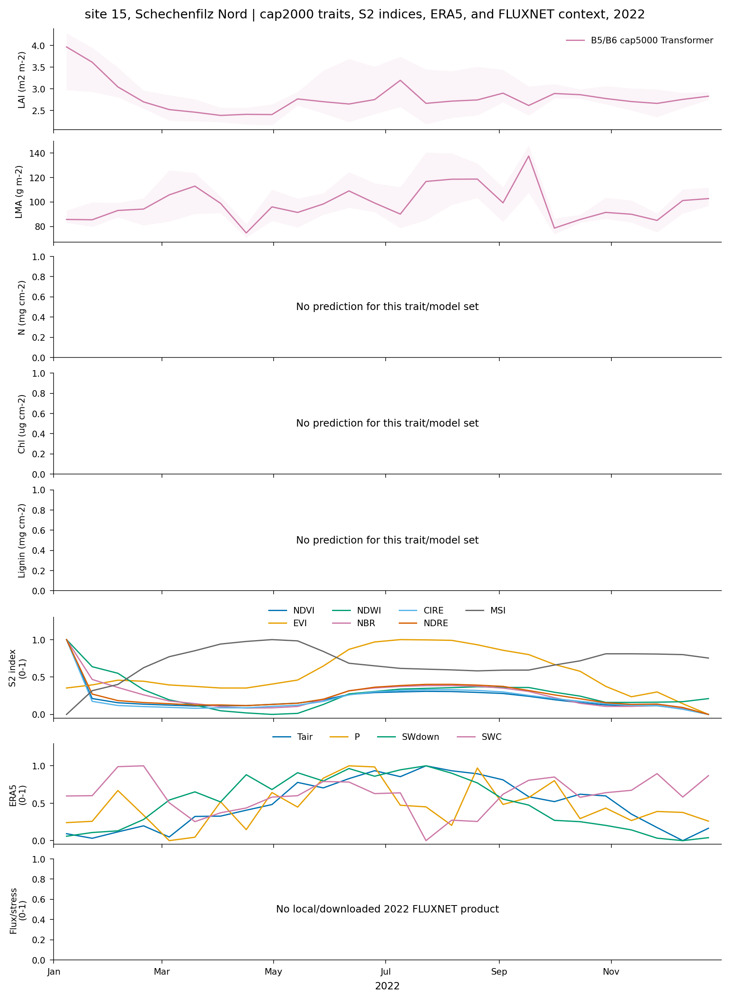

### site 17

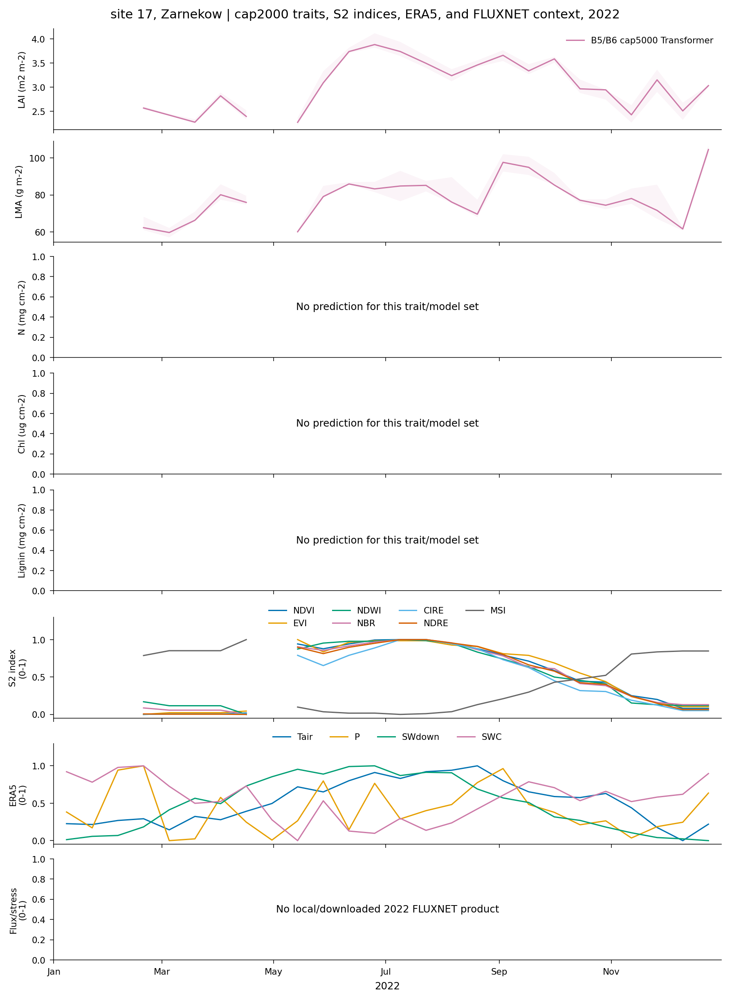

### site 20

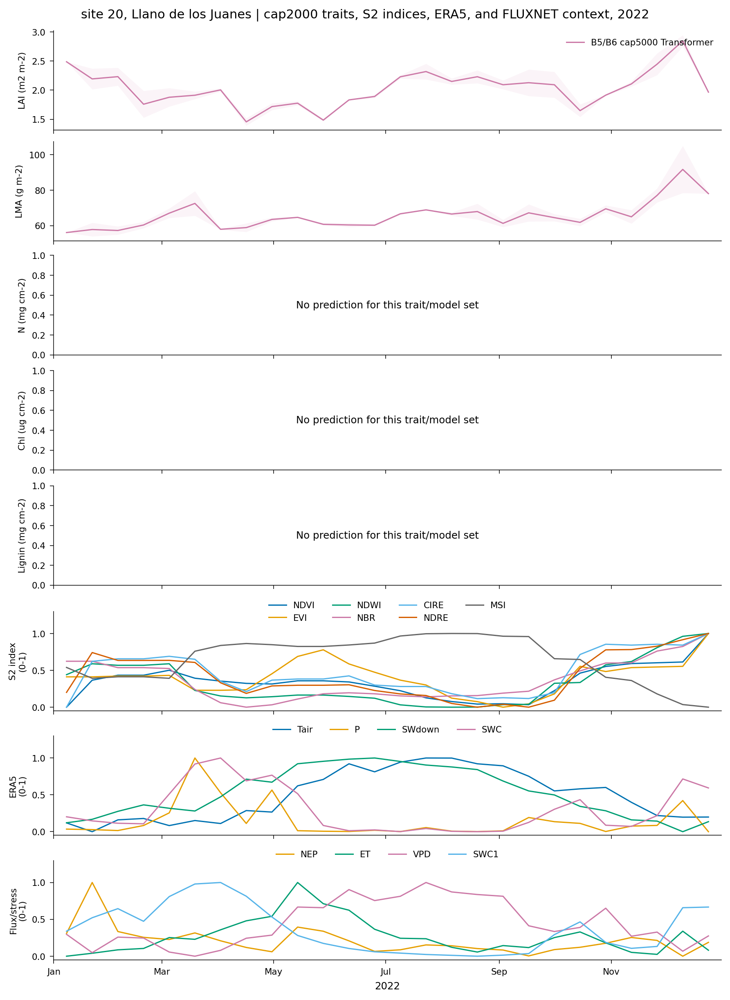

### site 22

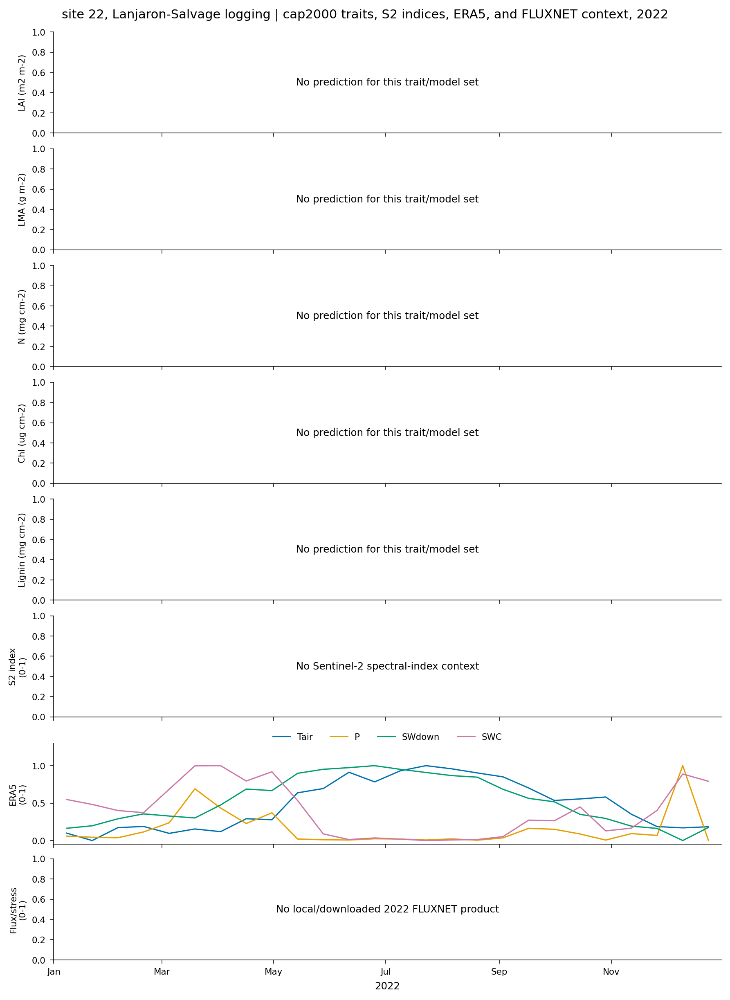

### site 23

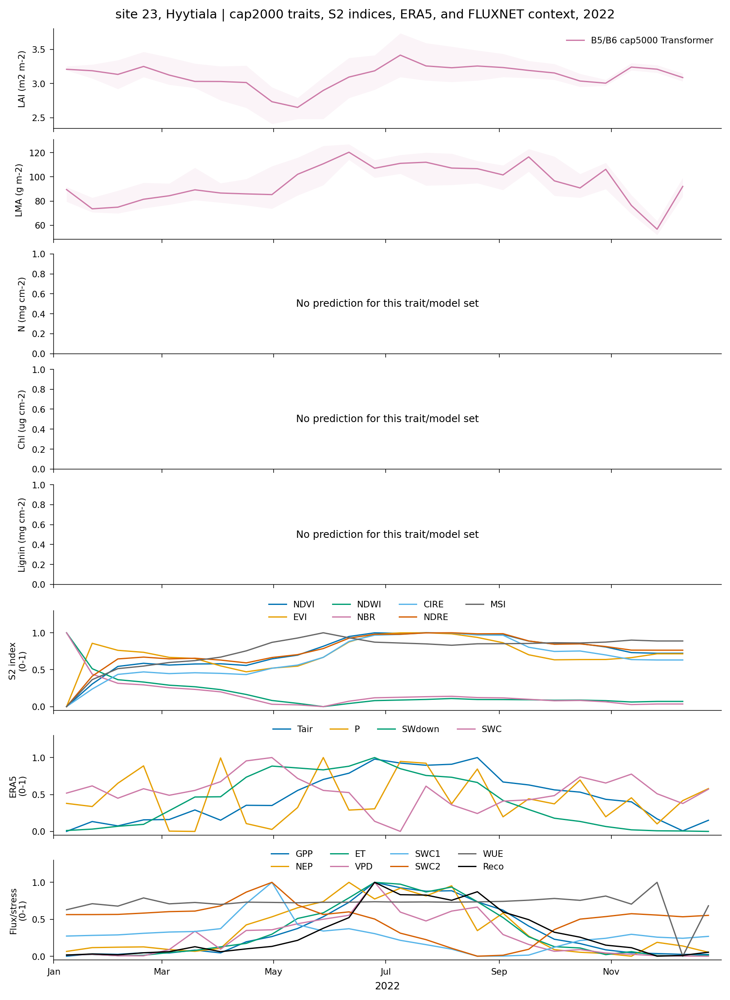

### site 24

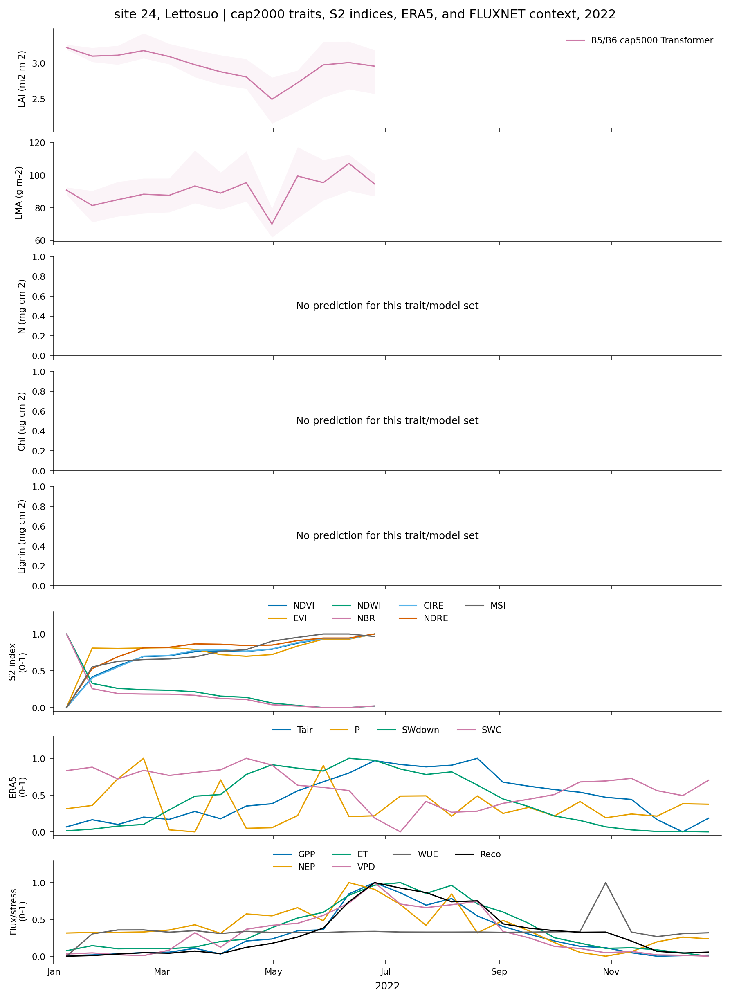

### site 25

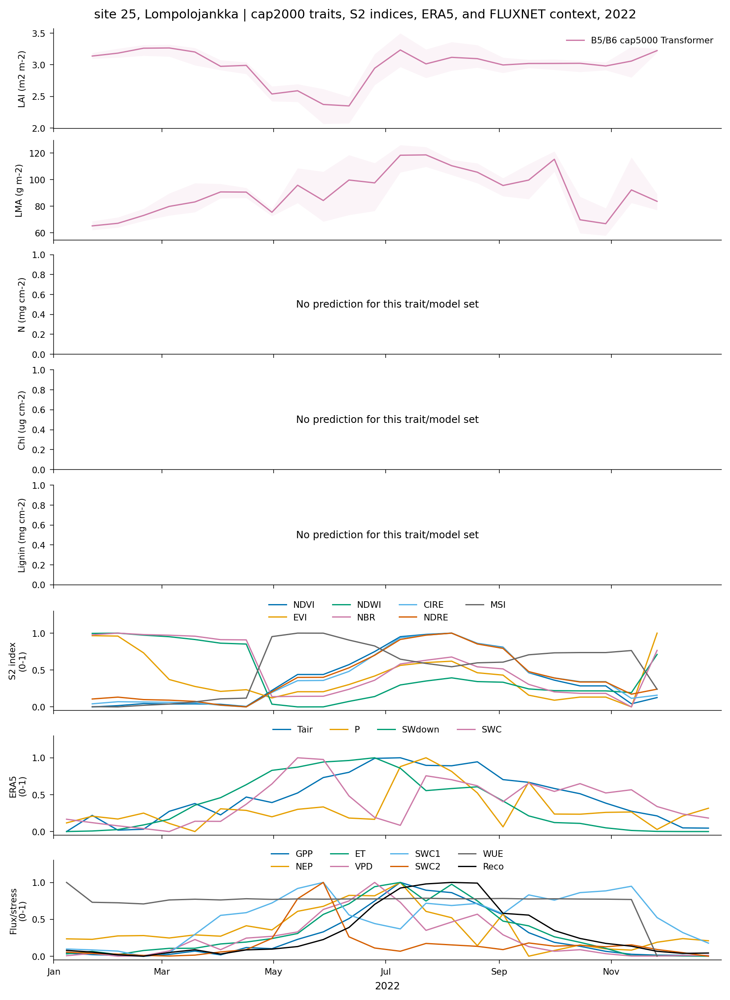

### site 26

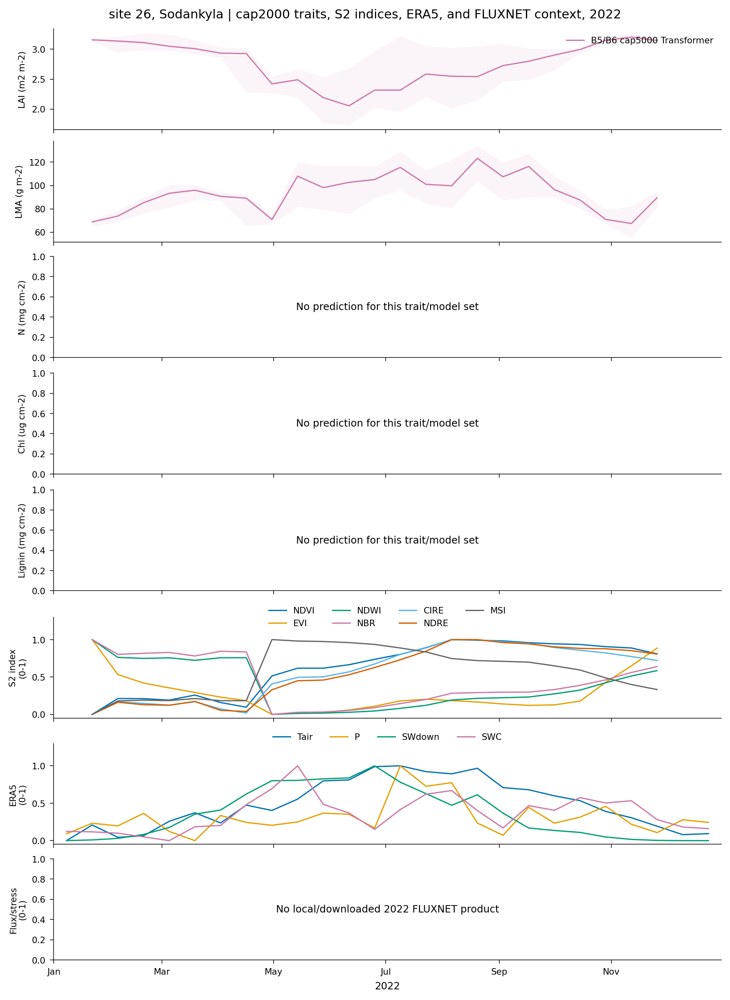

### site 28

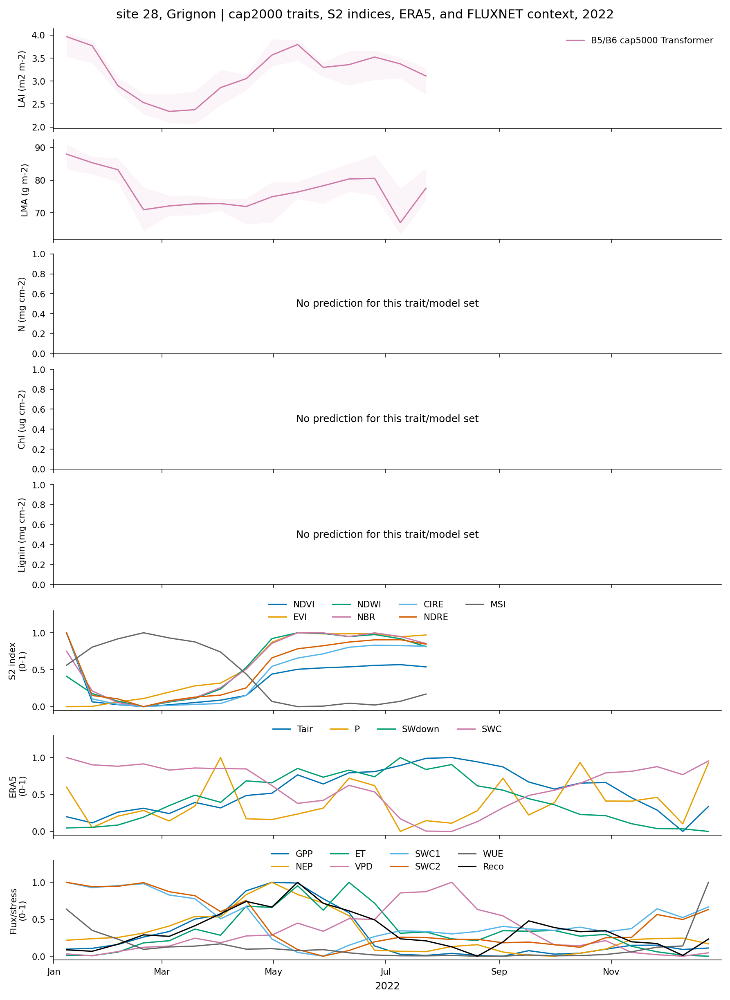

### site 29

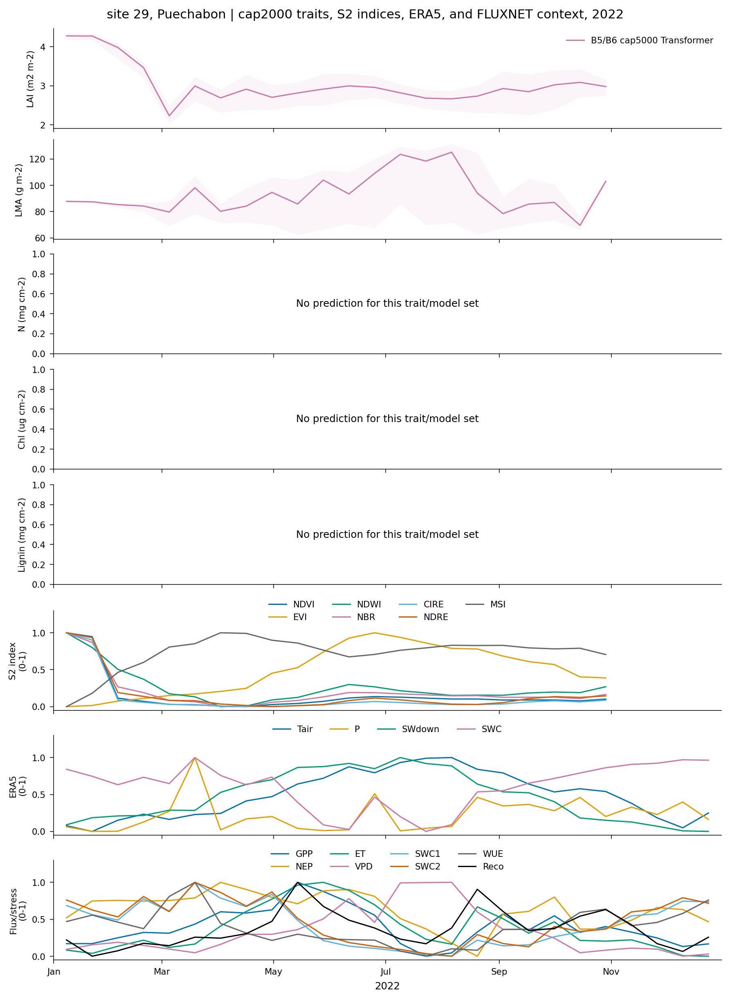

### site 32

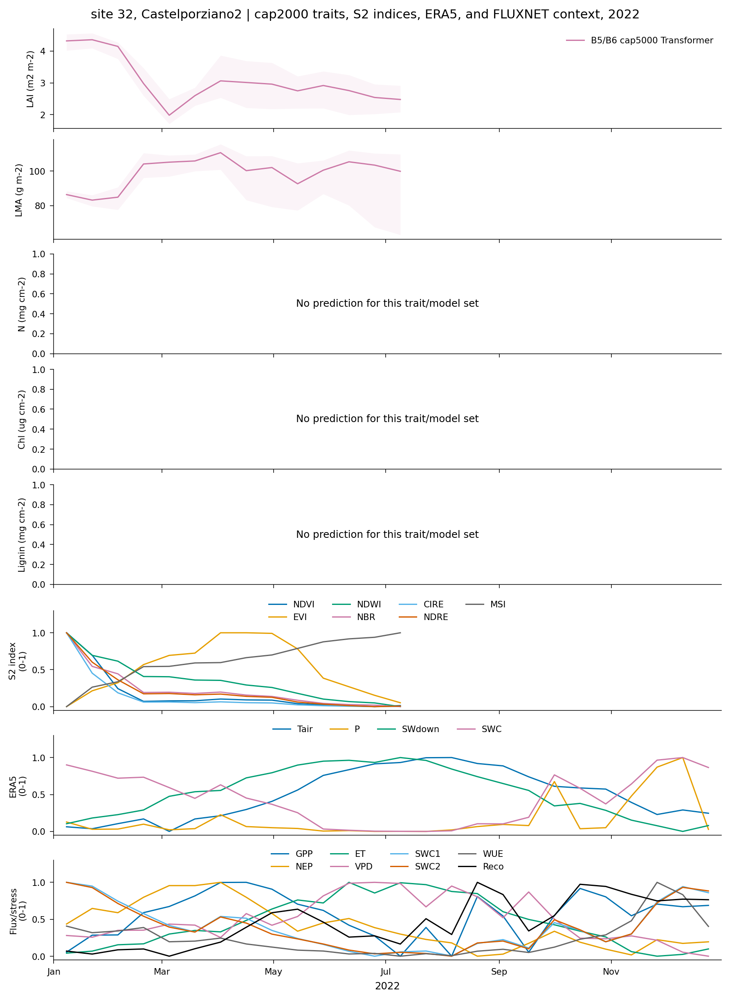

### site 33

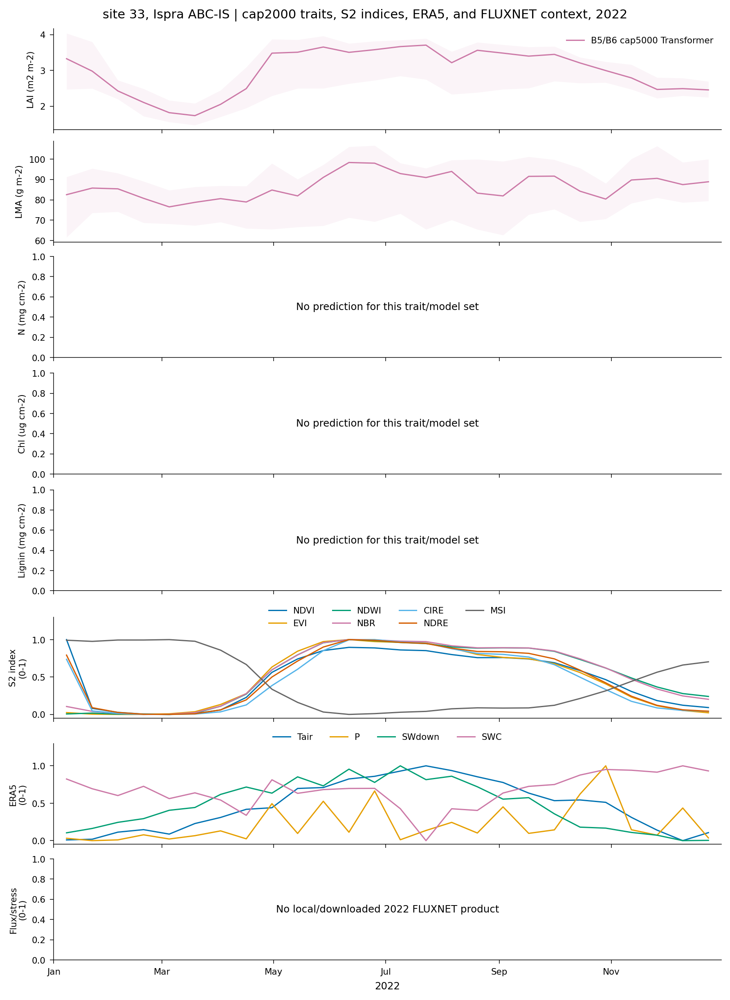

### site 35

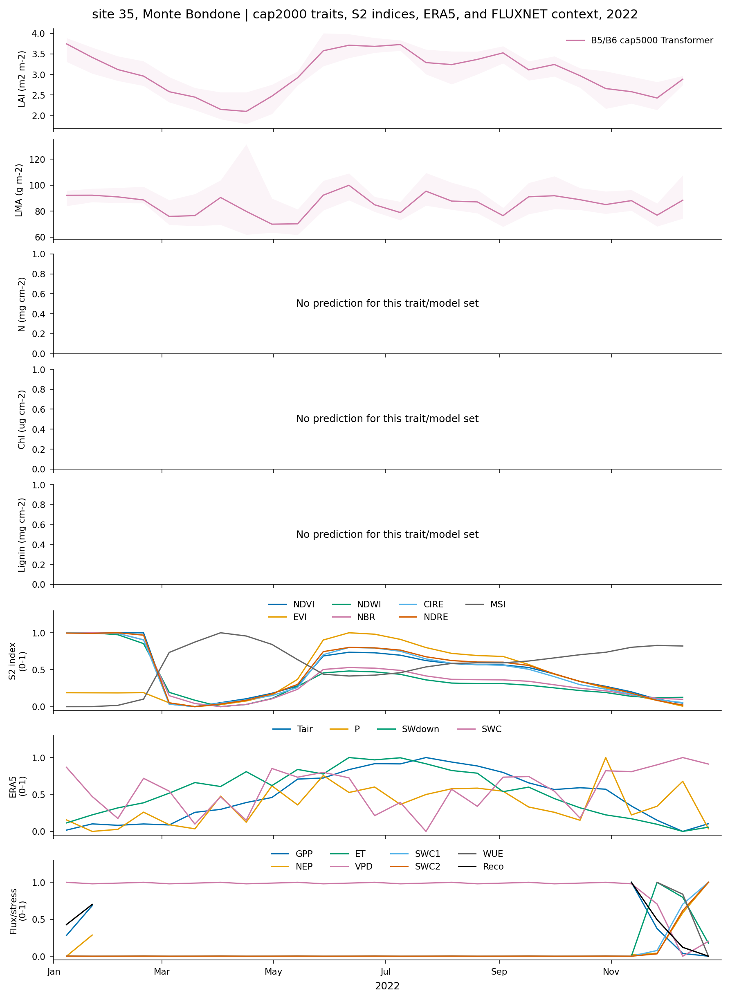

### site 37

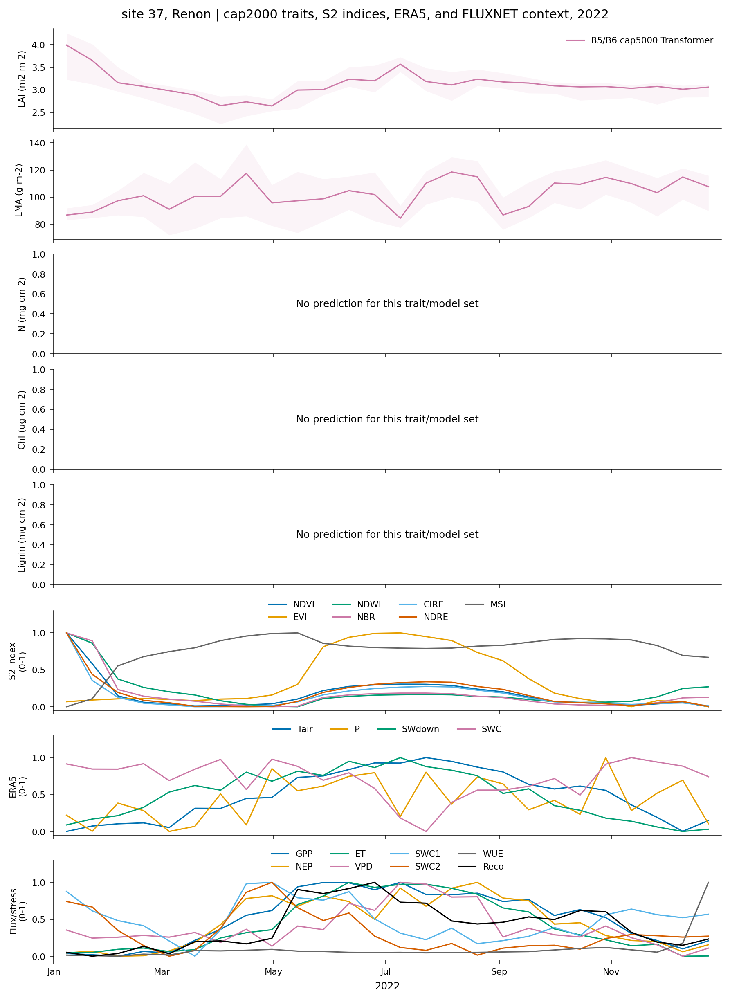

### site 39

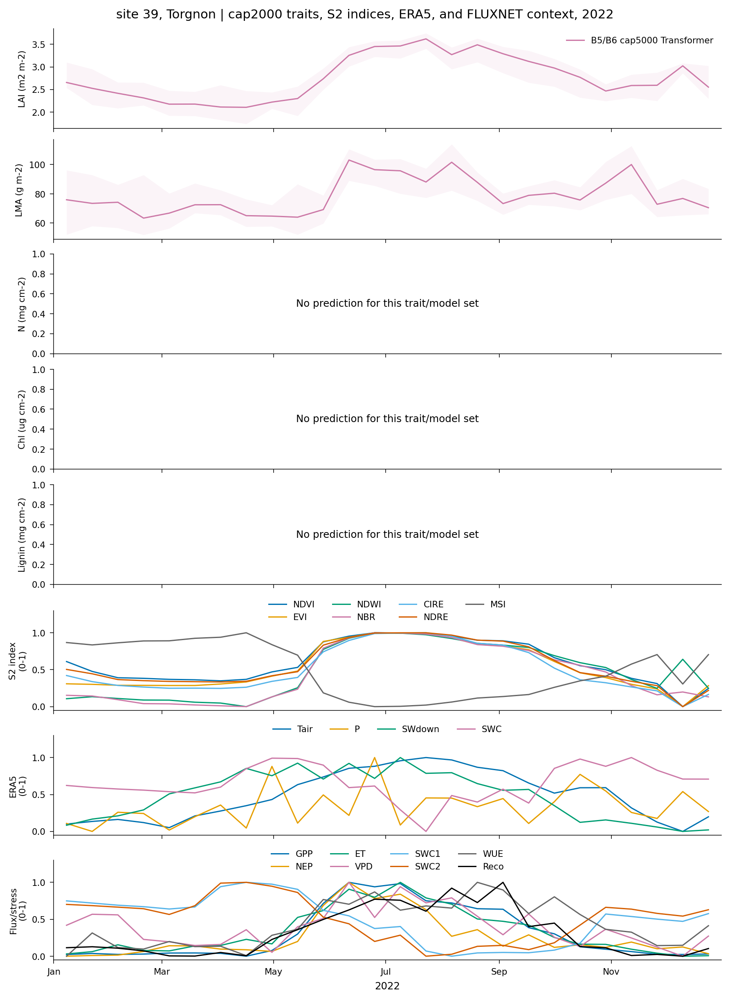

### site 40

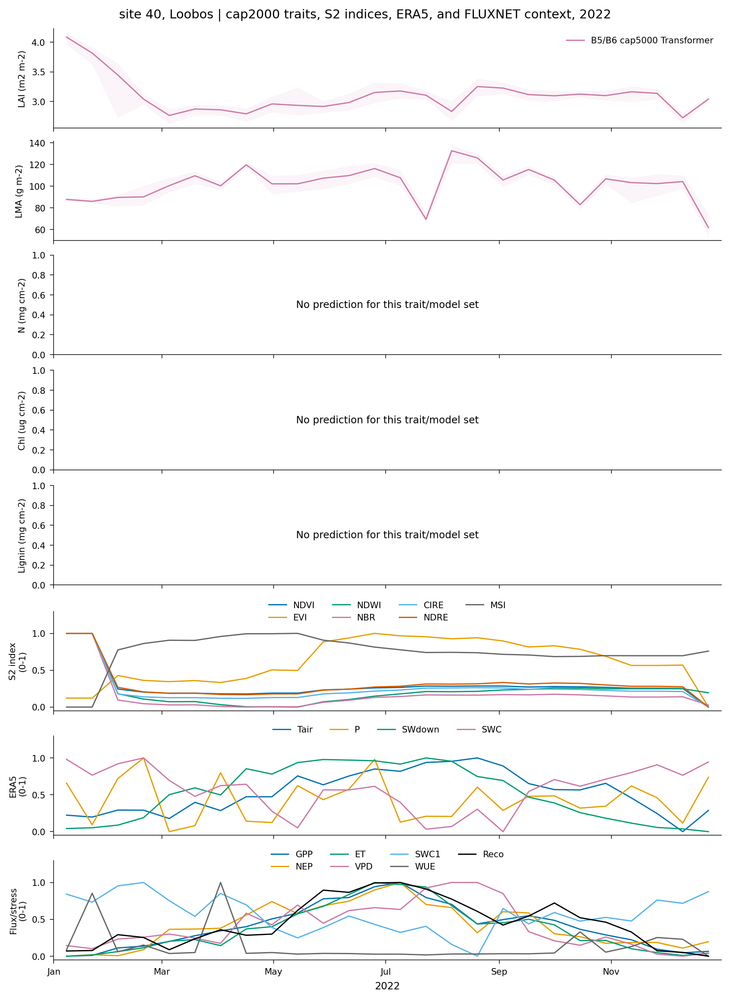

### site 41

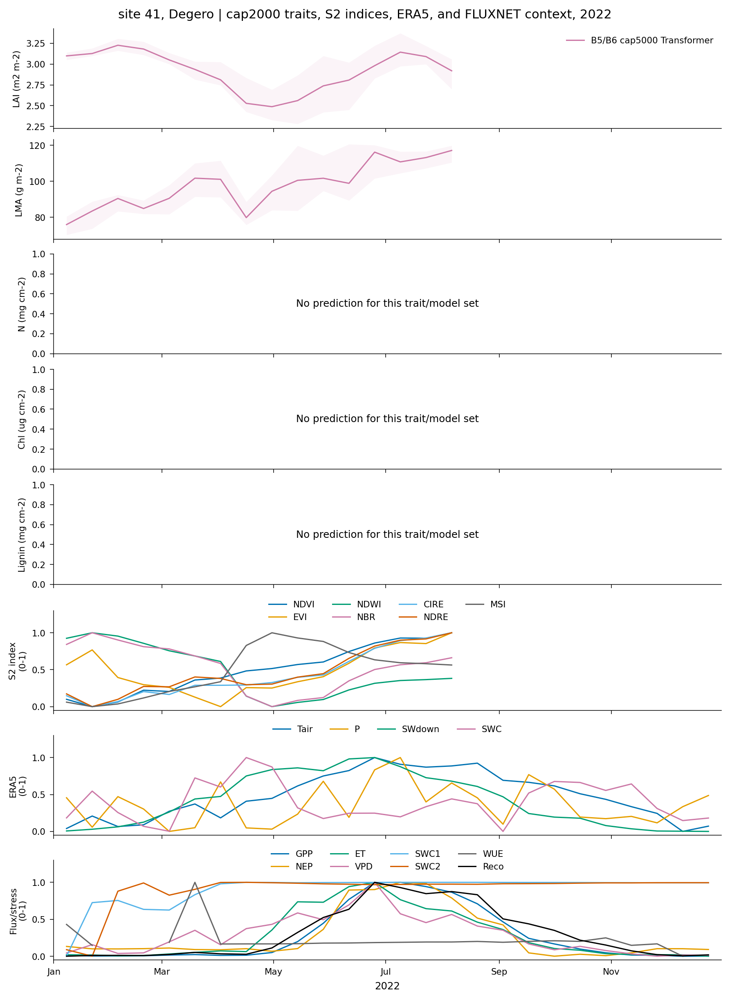

### site 43

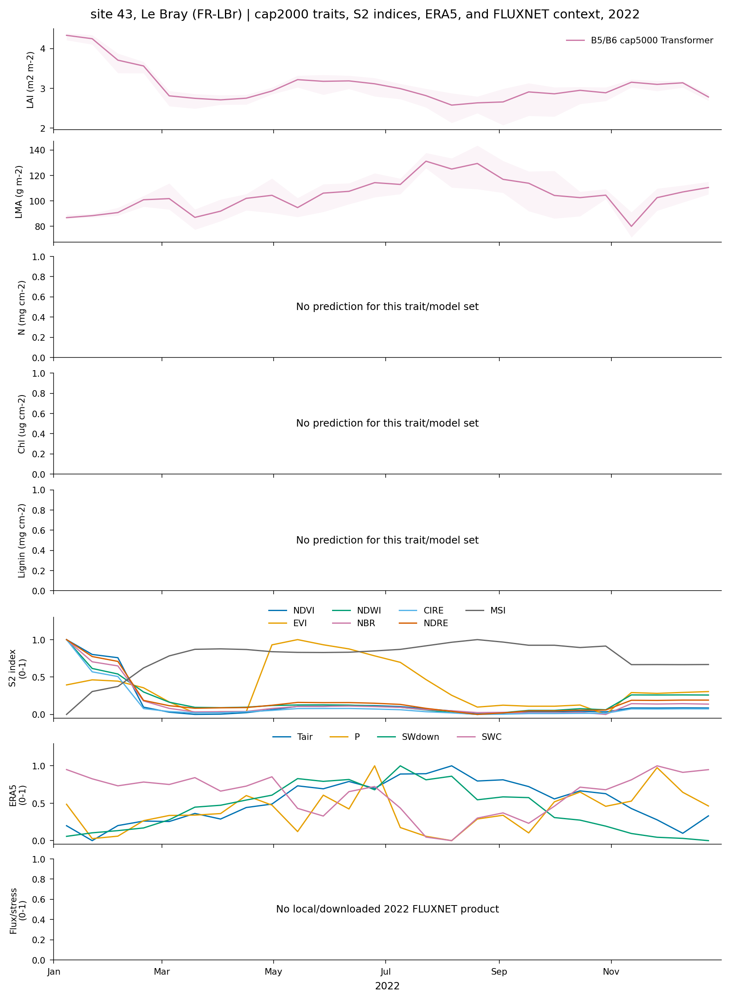

### site 44

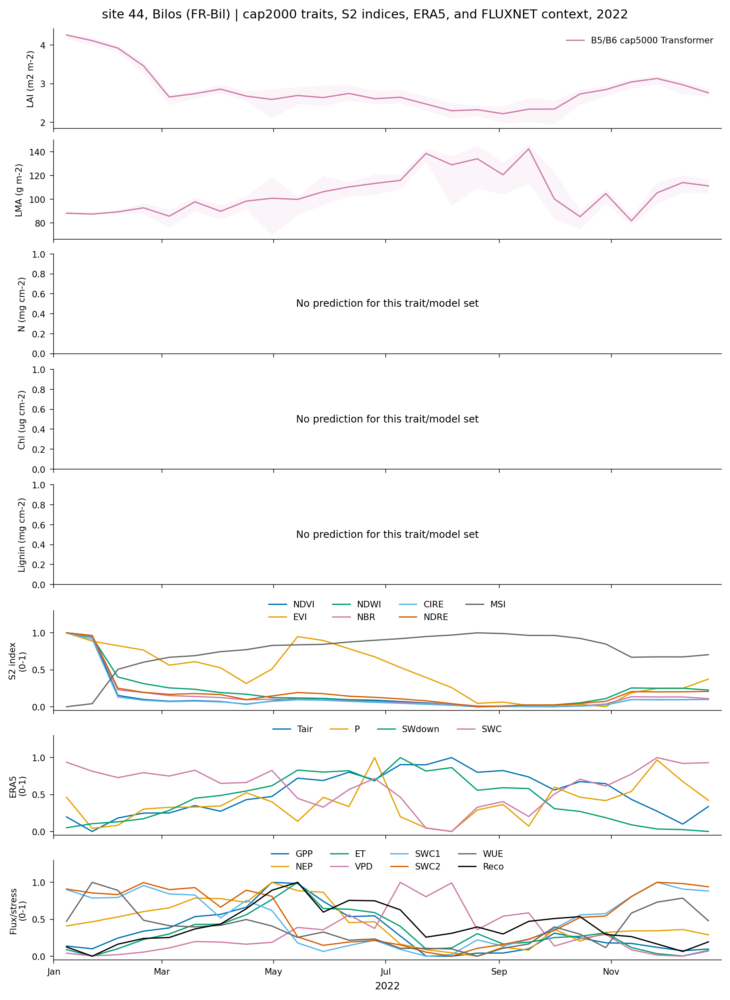

### site 46

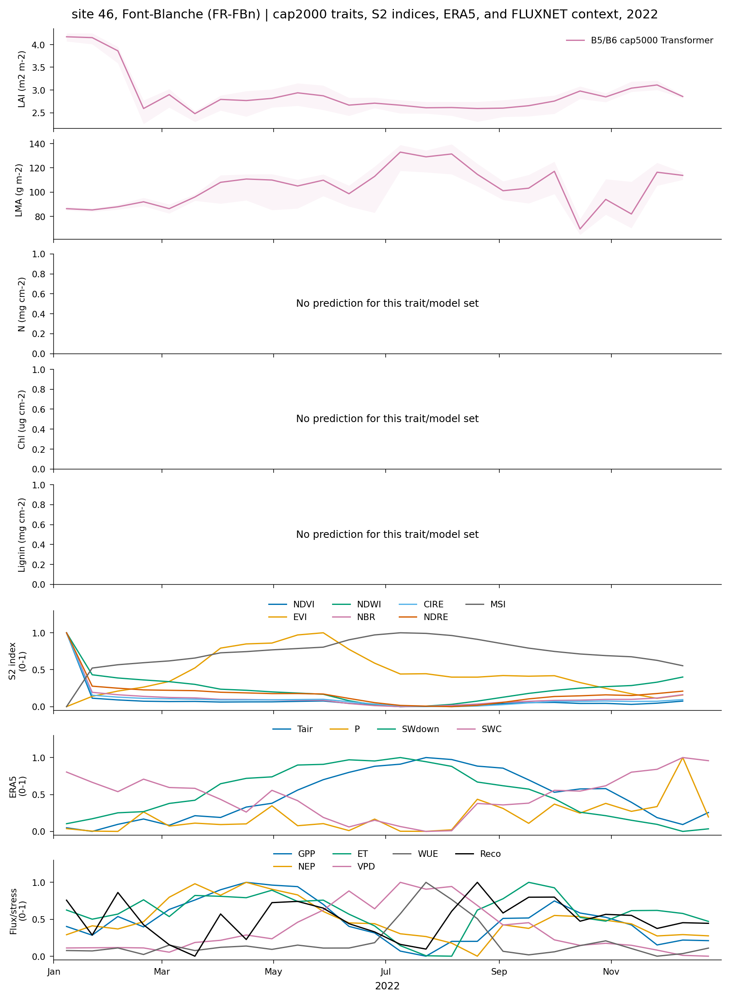

### site 47

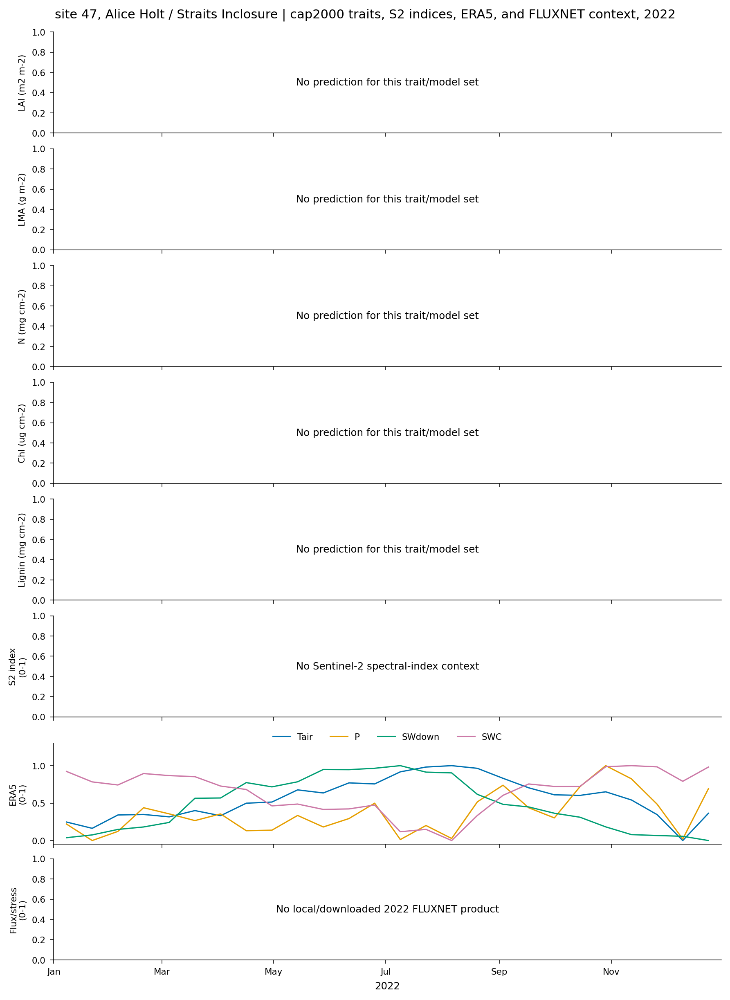

### site 48

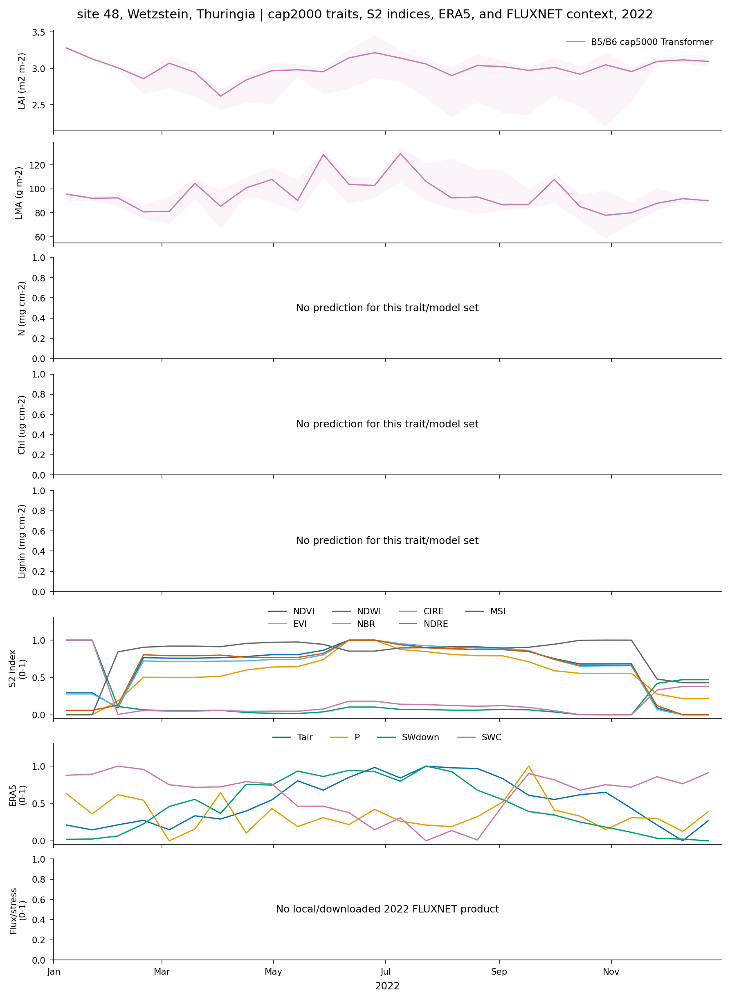

### site 49

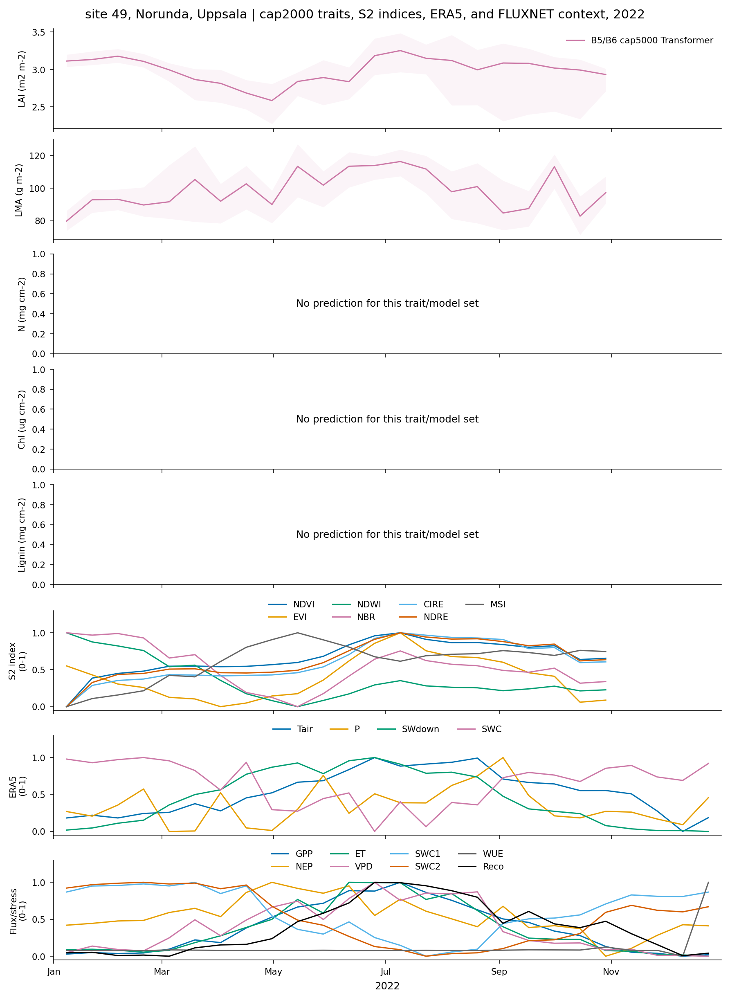

### site 52

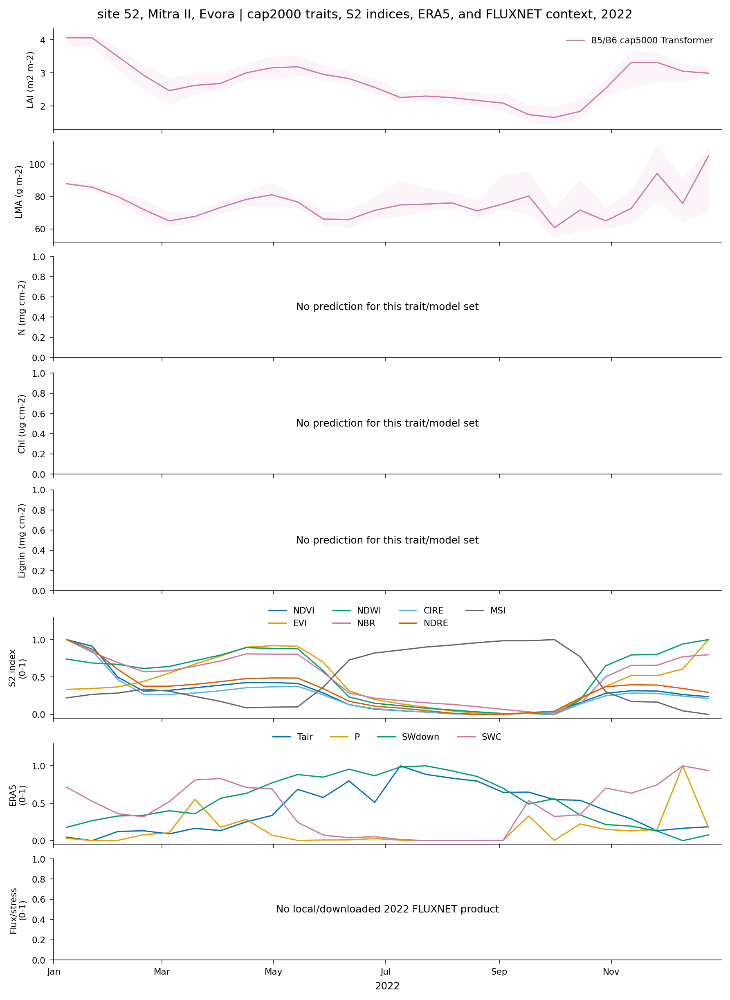

### site 53

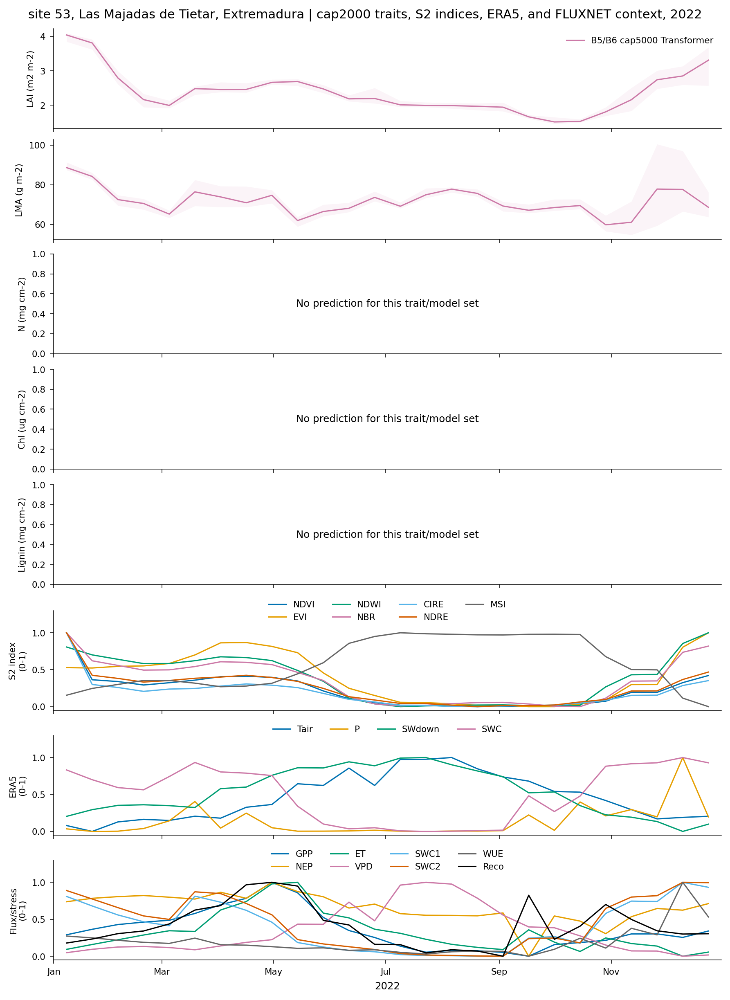

### site 54

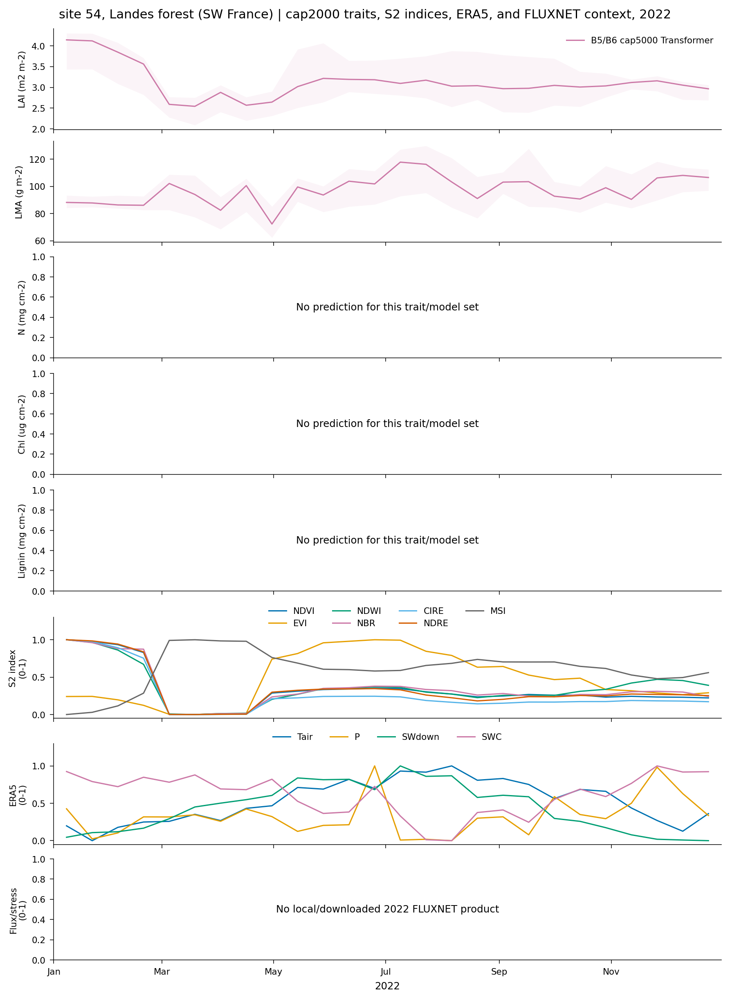

### site 56

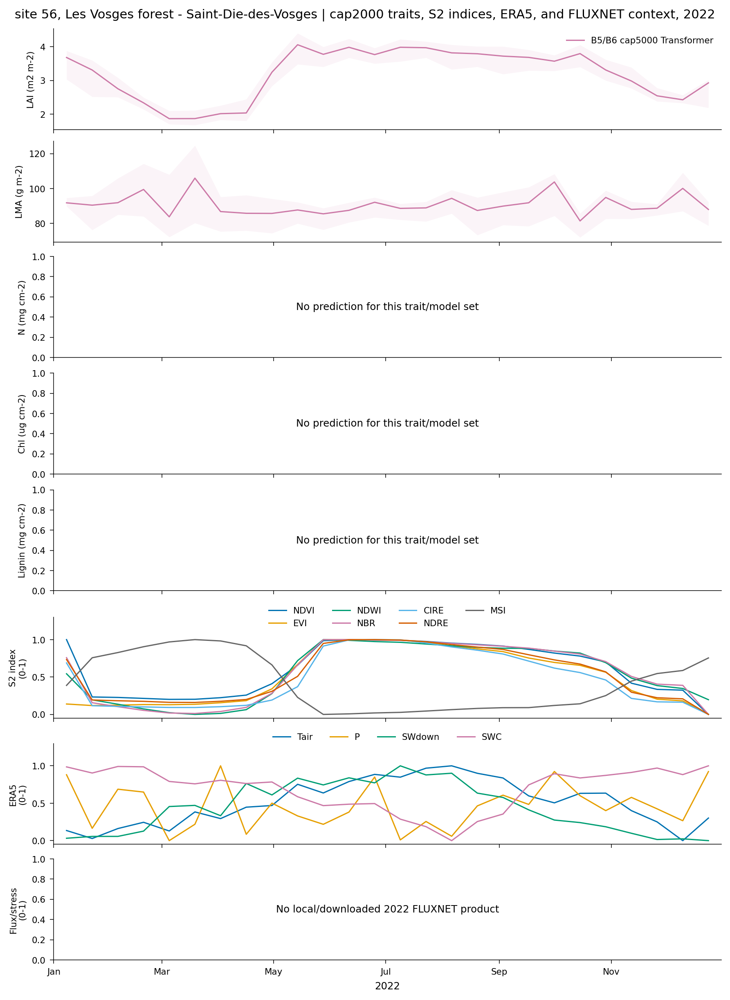

### site 57

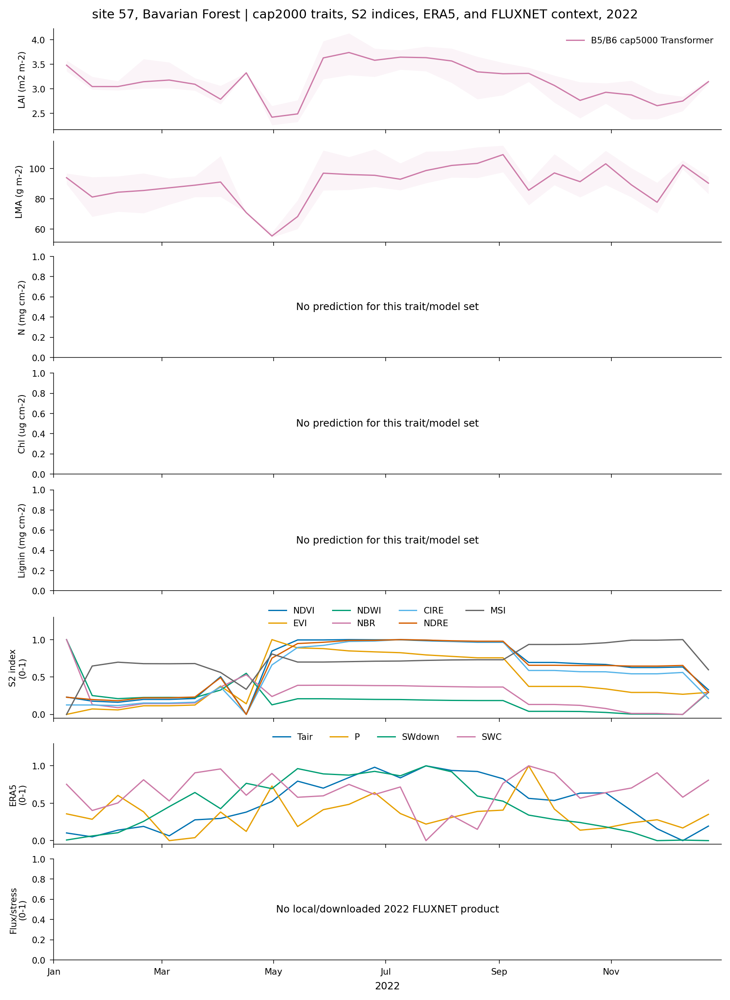

In [36]:
for site_id in MAPPING.site_id.astype(int).tolist():
    image_path = FIG_DIR / f"site_{site_id:02d}_cap2000_traits_flux_2022.png"
    if image_path.exists():
        display(Markdown(f"### site {site_id}"))
        display(Image(filename=str(image_path)))


## Tables


In [37]:
display(Markdown("### FLUXNET context"))
display(FLUX.head(20))

display(Markdown("### Trait predictions"))
display(PRED.head(20))

display(Markdown("### Sentinel-2 spectral context"))
display(SPECTRAL.head(20))

display(Markdown("### ERA5-Land context"))
display(ERA5.head(20))


### FLUXNET context

,site_id,site_name,date,GPP_NT_VUT_REF,NEP_VUT_REF,ET_F_MDS_mm_day,VPD_F_MDS,SWC_F_MDS_1,SWC_F_MDS_2,WUE_GPP_ET,RECO_NT_VUT_REF,NEE_VUT_REF,LE_F_MDS
0,0,Neustift,2022-01-08,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,0,Neustift,2022-01-22,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,0,Neustift,2022-02-05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,0,Neustift,2022-02-19,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,0,Neustift,2022-03-05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,0,Neustift,2022-03-19,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,0,Neustift,2022-04-02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,0,Neustift,2022-04-16,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,0,Neustift,2022-04-30,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,0,Neustift,2022-05-14,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Trait predictions

,site_id,site_label,date,model,model_label,trait,trait_label,prediction_median,prediction_p10,prediction_p90,n_pixels,valid_obs_median
0,0,"site 0, Neustift",2022-01-08,transformer_b5b6_cap5000,B5/B6 cap5000 Transformer,LAI,LAI (m2 m-2),3.827882,2.888756,4.249798,121,4.0
1,0,"site 0, Neustift",2022-01-22,transformer_b5b6_cap5000,B5/B6 cap5000 Transformer,LAI,LAI (m2 m-2),3.576272,2.814700,4.047834,121,4.0
2,0,"site 0, Neustift",2022-02-05,transformer_b5b6_cap5000,B5/B6 cap5000 Transformer,LAI,LAI (m2 m-2),3.263499,2.675400,3.654390,121,7.0
3,0,"site 0, Neustift",2022-02-19,transformer_b5b6_cap5000,B5/B6 cap5000 Transformer,LAI,LAI (m2 m-2),2.641862,2.212279,3.058969,121,8.0
4,0,"site 0, Neustift",2022-03-05,transformer_b5b6_cap5000,B5/B6 cap5000 Transformer,LAI,LAI (m2 m-2),2.591330,1.917106,3.039975,121,8.0
5,0,"site 0, Neustift",2022-03-19,transformer_b5b6_cap5000,B5/B6 cap5000 Transformer,LAI,LAI (m2 m-2),2.389501,1.736088,2.905288,121,8.0
6,0,"site 0, Neustift",2022-04-02,transformer_b5b6_cap5000,B5/B6 cap5000 Transformer,LAI,LAI (m2 m-2),2.342486,1.705814,2.795273,121,8.0
7,0,"site 0, Neustift",2022-04-16,transformer_b5b6_cap5000,B5/B6 cap5000 Transformer,LAI,LAI (m2 m-2),2.533251,2.101569,2.728413,121,8.0
8,0,"site 0, Neustift",2022-04-30,transformer_b5b6_cap5000,B5/B6 cap5000 Transformer,LAI,LAI (m2 m-2),2.499685,2.151914,2.732260,121,8.0
9,0,"site 0, Neustift",2022-05-14,transformer_b5b6_cap5000,B5/B6 cap5000 Transformer,LAI,LAI (m2 m-2),2.745744,2.557542,3.103691,121,8.0


### Sentinel-2 spectral context

,site_id,date,NDVI_median,EVI_median,NDWI_median,NBR_median,CIRE_median,NDRE_median,MSI_median
0,0,2022-01-08,0.593992,0.253050,0.257448,0.459717,1.524898,0.420671,0.590527
1,0,2022-01-22,0.492114,0.258983,0.281096,0.380320,1.128631,0.354788,0.561163
2,0,2022-02-05,0.376308,0.251262,0.169385,0.270944,0.850516,0.288454,0.710301
3,0,2022-02-19,0.328087,0.247690,0.112487,0.214799,0.710981,0.252754,0.797774
4,0,2022-03-05,0.320074,0.250118,0.087809,0.197092,0.672556,0.240817,0.838558
5,0,2022-03-19,0.317610,0.251890,0.073662,0.182404,0.672258,0.238988,0.862784
6,0,2022-04-02,0.317980,0.266427,0.069503,0.189041,0.668286,0.234202,0.870027
7,0,2022-04-16,0.326722,0.283192,0.089406,0.208724,0.688264,0.237352,0.835864
8,0,2022-04-30,0.378769,0.345168,0.146305,0.276241,0.827989,0.276635,0.744736
9,0,2022-05-14,0.411477,0.397472,0.175377,0.311304,0.924757,0.298488,0.701581


### ERA5-Land context

,site_id,site_name,date,2m_temperature_C,total_precipitation_mm,surface_solar_radiation_downwards_MJ_m2_day,volumetric_soil_water_layer_1
0,0,Neustift,2022-01-08,-7.672529,26.060414,5.526555,0.265219
1,0,Neustift,2022-01-22,-7.426103,18.961482,6.848047,0.259815
2,0,Neustift,2022-02-05,-6.721889,86.773312,6.989184,0.255811
3,0,Neustift,2022-02-19,-6.296787,39.865054,10.104418,0.252307
4,0,Neustift,2022-03-05,-8.736735,4.135997,15.505320,0.248869
5,0,Neustift,2022-03-19,-1.434114,7.946248,17.178819,0.261544
6,0,Neustift,2022-04-02,-1.249740,56.805893,15.716144,0.268493
7,0,Neustift,2022-04-16,0.991296,26.596708,20.724805,0.319433
8,0,Neustift,2022-04-30,1.858798,96.341841,17.526426,0.357605
9,0,Neustift,2022-05-14,8.111411,77.952627,20.500724,0.381347
